# Análises do artigo: comércio mundial da cadeia do níquel antes e depois da RCEP

Este notebook gera **todas** as figuras e tabelas de dados do artigo. Cada passo tem duas partes:

- **Tratamento**: a transformação aplicada aos dados, feita com as funções de `src/niquel/`;
- **Validação**: conferências que precisam passar antes de seguir (somas de controle contra a base
  bruta, unicidade de chaves, participações somando 100%, recálculo manual de um caso). Uma validação
  que falha interrompe a execução com `AssertionError`.

Saídas: figuras em `outputs/figuras/` (PNG, 300 dpi), dados de cada figura em
`outputs/tabelas/dados_figuras/` e tabelas em `outputs/tabelas/` (CSV e uma planilha consolidada
`tabelas_artigo.xlsx`).

| Passo | Conteúdo |
|---|---|
| 1 | Extração dos fluxos da cadeia a partir do parquet bruto |
| 2 | Classificação: elo, região, grupo RCEP |
| 3 | Volumes anuais (valor e quantidade) por SH6 e por elo |
| 4 | Participação dos principais exportadores e importadores; concentração |
| 5 | Participação das macrorregiões |
| 6 | Participação de cada membro da RCEP antes e depois da sua adesão |
| 7 | Comércio intra-RCEP e matriz China/ASEAN/demais RCEP/resto do mundo |
| 8 | Painéis replicados para cada SH6 do núcleo e cada elo |
| 9 | Mapas do comércio mundial (participação por país e principais fluxos) |
| 10 | Composição dos parceiros e volume dos membros da RCEP, com placebos |
| 11 | Síntese para o resumo: três figuras da cadeia destacada (mundo, Ásia, RCEP) |
| 12 | Inventário das saídas |

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ / "src"))

import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from niquel import config as cfg, extracao as ex, indicadores as ind, graficos as gr, mapas as mp, parceiros as pa, sintese as si

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
cfg.DIR_TAB.mkdir(parents=True, exist_ok=True)
TABELAS = {}  # nome -> DataFrame, consolidadas no xlsx ao final


def salvar_tabela(df, nome):
    """Grava a tabela em CSV (UTF-8 com BOM, abre direto no Excel) e guarda para o xlsx."""
    df.to_csv(cfg.DIR_TAB / f"{nome}.csv", encoding="utf-8-sig", index=False)
    TABELAS[nome] = df
    print(f"tabela salva: outputs/tabelas/{nome}.csv ({len(df)} linhas)")


def ok(msg):
    print("✔", msg)

## Passo 1. Extração

### Tratamento
Lê do parquet bruto, com filtro do pyarrow, os fluxos dos SH6 listados em `config.CADEIA` e grava em
`data/processed/baci_cadeia_niquel.parquet`. Use `forcar=True` depois de alterar a lista de códigos.

In [2]:
fluxos = ex.fluxos_cadeia(forcar=False)
paises = ex.tabela_paises()
print(f"{len(fluxos):,} fluxos | {fluxos['sh6'].nunique()} SH6 | {fluxos['ano'].min()}–{fluxos['ano'].max()}")
fluxos.sample(5, random_state=42)

1,000,195 fluxos | 59 SH6 | 2012–2024


,ano,exp,imp,sh6,valor,qtd
568409,2024,svk,idn,722300,7959.0,0.087
190114,2015,hun,gbr,722230,20099.0,0.133
318533,2018,chn,pak,722012,415053.0,360.980
713133,2013,hun,mex,850730,1142.0,0.025
443865,2018,kor,bel,721934,12638452.0,10130.943


### Validação
1. Para cada SH6 do núcleo, em três anos, soma e número de linhas da extração iguais aos da base bruta
   (lidos de novo, por consulta independente).
2. Nenhuma duplicata da chave ano × exportador × importador × SH6.
3. Todos os SH6 configurados presentes em todos os anos; nenhum valor ausente ou não positivo.
4. Nenhum fluxo de um país para ele mesmo.

In [3]:
if cfg.ARQ_BACI.exists():
    conferencia = []
    for sh6 in cfg.SH6_NUCLEO:
        for ano in (2012, 2018, 2024):
            bruto_valor, bruto_linhas = ex.soma_bruta(sh6, ano)
            sel = fluxos[(fluxos["sh6"] == sh6) & (fluxos["ano"] == ano)]
            conferencia.append((sh6, ano, bruto_valor, sel["valor"].sum(), bruto_linhas, len(sel)))
    conferencia = pd.DataFrame(conferencia, columns=["sh6", "ano", "valor_bruto", "valor_extraido", "linhas_bruto", "linhas_extraidas"])
    assert np.allclose(conferencia["valor_bruto"], conferencia["valor_extraido"], rtol=1e-12)
    assert (conferencia["linhas_bruto"] == conferencia["linhas_extraidas"]).all()
    ok(f"extração idêntica à base bruta em {len(conferencia)} combinações SH6 × ano")
else:  # cópia sem o parquet bruto (1,35 GB): usa as extrações versionadas em data/processed/
    print("parquet bruto ausente: conferência contra a base bruta não executada")

assert not fluxos.duplicated(["ano", "exp", "imp", "sh6"]).any()
ok("chave ano × exp × imp × sh6 única")

presenca = fluxos.groupby("sh6")["ano"].nunique()
assert set(presenca.index) == set(cfg.TODOS_SH6) and (presenca == len(cfg.ANOS)).all(), presenca[presenca < len(cfg.ANOS)]
ok(f"{len(presenca)} SH6 presentes nos {len(cfg.ANOS)} anos")

assert fluxos["valor"].notna().all() and (fluxos["valor"] > 0).all()
ok(f"valores positivos e sem ausências (mínimo US$ {fluxos['valor'].min():,.0f})")

assert not (fluxos["exp"] == fluxos["imp"]).any()
ok("nenhum fluxo de um país para ele mesmo")
conferencia if cfg.ARQ_BACI.exists() else None

parquet bruto ausente: conferência contra a base bruta não executada


✔ chave ano × exp × imp × sh6 única
✔ 59 SH6 presentes nos 13 anos
✔ valores positivos e sem ausências (mínimo US$ 1)


✔ nenhum fluxo de um país para ele mesmo


## Passo 2. Classificação

### Tratamento
Acrescenta a cada fluxo o elo da cadeia e o rótulo do produto (`config.CADEIA`), a macrorregião do
exportador e do importador (sub-regiões M49 da ONU agrupadas em `config.MACRORREGIAO`) e o grupo de
cada lado: China, ASEAN, demais membros da RCEP (Japão, Coreia do Sul, Austrália, Nova Zelândia) ou
resto do mundo.

In [4]:
df = ind.preparar(fluxos, paises)
df[["ano", "exp", "imp", "sh6", "elo", "produto", "reg_exp", "reg_imp", "grupo_exp", "grupo_imp", "valor"]].sample(5, random_state=1)

,ano,exp,imp,sh6,elo,produto,reg_exp,reg_imp,grupo_exp,grupo_imp,valor
821178,2013,mys,irl,722300,6. Aço inoxidável,Aço inox: fios (722300),Sudeste Asiático,Europa,ASEAN,Resto do mundo,3782.0
86016,2021,usa,mex,721911,6. Aço inoxidável,Aço inox: laminados planos (≥600 mm) (721911),América do Norte,América Latina e Caribe,Resto do mundo,Resto do mundo,766934.0
238085,2022,chn,fin,850730,7. Baterias,Acumuladores de níquel-cádmio,Ásia Oriental,Europa,China,Resto do mundo,136035.0
895670,2020,tur,fji,721921,6. Aço inoxidável,Aço inox: laminados planos (≥600 mm) (721921),Ásia Ocidental e Central,Oceania,Resto do mundo,Resto do mundo,5266.0
400159,2023,nor,usa,750720,5. Semimanufaturas e sucata,Acessórios para tubos de níquel,Europa,América do Norte,Resto do mundo,Resto do mundo,76734.0


### Validação
1. Nenhum fluxo sem elo, região ou grupo.
2. Os 15 membros da RCEP aparecem na base; Mianmar é o único sem data de vigência.
3. A classificação não altera o total: a soma por elo, por região e por grupo reproduz o total anual.
4. Conferência manual da classificação de alguns países.

In [5]:
for col in ["elo", "produto", "reg_exp", "reg_imp", "grupo_exp", "grupo_imp"]:
    assert df[col].notna().all() and (df[col] != "").all(), f"ausências em {col}"
ok("todos os fluxos classificados")

assert set(cfg.RCEP) <= set(paises["iso3"]) and len(cfg.RCEP) == 15
assert [c for c, d in cfg.RCEP_VIGENCIA.items() if d is None] == ["mmr"]
ok("15 membros da RCEP na base; só Mianmar sem data")

total_ano = df.groupby("ano", as_index=False)["valor"].sum()
for chave in ["elo", "reg_exp", "reg_imp", "grupo_exp"]:
    soma = df.groupby(["ano", chave], as_index=False)["valor"].sum()
    print(" ", chave, ind.checar_total(soma, total_ano, "ano"))

amostra_paises = paises.set_index("iso3").loc[["chn", "idn", "phl", "jpn", "ncl", "bra", "rus", "can"],
                                             ["nome", "subregiao_onu", "macrorregiao"]]
amostra_paises["grupo"] = [ind.grupo_rcep(c) for c in amostra_paises.index]
amostra_paises

✔ todos os fluxos classificados
✔ 15 membros da RCEP na base; só Mianmar sem data
  elo OK: 13 totais conferidos, maior diferença relativa 0.00e+00
  reg_exp OK: 13 totais conferidos, maior diferença relativa 0.00e+00


  reg_imp OK: 13 totais conferidos, maior diferença relativa 0.00e+00
  grupo_exp OK: 13 totais conferidos, maior diferença relativa 0.00e+00


,nome,subregiao_onu,macrorregiao,grupo
iso3,,,,
chn,China,Eastern Asia,Ásia Oriental,China
idn,Indonésia,South-eastern Asia,Sudeste Asiático,ASEAN
phl,Filipinas,South-eastern Asia,Sudeste Asiático,ASEAN
jpn,Japão,Eastern Asia,Ásia Oriental,Demais RCEP
ncl,Nova Caledônia,Melanesia,Oceania,Resto do mundo
bra,Brasil,South America,América Latina e Caribe,Resto do mundo
rus,Rússia,Eastern Europe,Europa,Resto do mundo
can,Canadá,Northern America,América do Norte,Resto do mundo


## Passo 3. Volumes anuais

### Tratamento
Por ano e produto: valor (US$ correntes), quantidade (toneladas), número de fluxos, cobertura da
quantidade (parcela do valor com quantidade informada) e valor unitário (US$/t, calculado só sobre os
fluxos com quantidade). Calculado por SH6 e por elo. Quantidades por elo somam toneladas de produtos
diferentes e servem só como referência; as figuras usam quantidades apenas por SH6.

In [6]:
tot_sh6 = ind.totais(df, "sh6")
tot_elo = ind.totais(df, "elo")
tot_sh6.query("sh6 == '750210'").round(2)

,ano,sh6,valor,qtd,n_fluxos,cobertura_qtd,valor_unit
40,2012,750210,1.317912e+10,741781.95,839,1.0,17766.84
99,2013,750210,1.329154e+10,861769.84,924,1.0,15423.53
158,2014,750210,1.648124e+10,975744.34,935,1.0,16890.94
217,2015,750210,1.614086e+10,1309939.50,1086,1.0,12321.84
276,2016,750210,1.099182e+10,1041741.19,999,1.0,10551.40
335,2017,750210,1.051509e+10,968568.60,1002,1.0,10856.32
394,2018,750210,1.161306e+10,863910.38,1021,1.0,13442.44
453,2019,750210,1.181474e+10,847461.06,1005,1.0,13941.34
512,2020,750210,9.483417e+09,659046.15,980,1.0,14389.61
571,2021,750210,1.633396e+10,903935.66,984,1.0,18069.82


### Validação
1. A soma dos SH6 de cada elo reproduz o total do elo.
2. A soma dos SH6 reproduz o total da extração.
3. Cobertura da quantidade por elo (para saber onde a série física é confiável).
4. Valor unitário do níquel refinado (750210) comparável à ordem de grandeza dos preços da LME
   (US$ 10–30 mil por tonelada no período).

In [7]:
soma_elo = tot_sh6.assign(elo=tot_sh6["sh6"].map(cfg.SH6_ELO)).groupby(["ano", "elo"], as_index=False)["valor"].sum()
print(" ", ind.checar_total(soma_elo, tot_elo, ["ano", "elo"]))
print(" ", ind.checar_total(tot_sh6, df, "ano"))

cobertura = tot_elo.pivot(index="ano", columns="elo", values="cobertura_qtd")
print("Cobertura mínima da quantidade por elo:")
display(cobertura.min().round(4).to_frame("cobertura_min"))

vu = tot_sh6.query("sh6 == '750210'").set_index("ano")["valor_unit"]
assert vu.between(8_000, 40_000).all(), vu
ok(f"valor unitário do 750210 entre US$ {vu.min():,.0f} e US$ {vu.max():,.0f} por tonelada")

  OK: 117 totais conferidos, maior diferença relativa 0.00e+00
  OK: 13 totais conferidos, maior diferença relativa 0.00e+00
Cobertura mínima da quantidade por elo:


,cobertura_min
elo,
1. Minério,1.0
2. Intermediários,1.0
3. Níquel refinado,1.0
4. Químicos de níquel,1.0
5. Semimanufaturas e sucata,1.0
6. Aço inoxidável,1.0
7. Baterias,1.0
8. Outros usos,1.0
9. Cátodos (aproximado),1.0


✔ valor unitário do 750210 entre US$ 10,551 e US$ 24,224 por tonelada


### Saídas do passo 3

tabela salva: outputs/tabelas/t01_volumes_anuais_sh6.csv (767 linhas)
tabela salva: outputs/tabelas/t02_volumes_anuais_elo.csv (117 linhas)


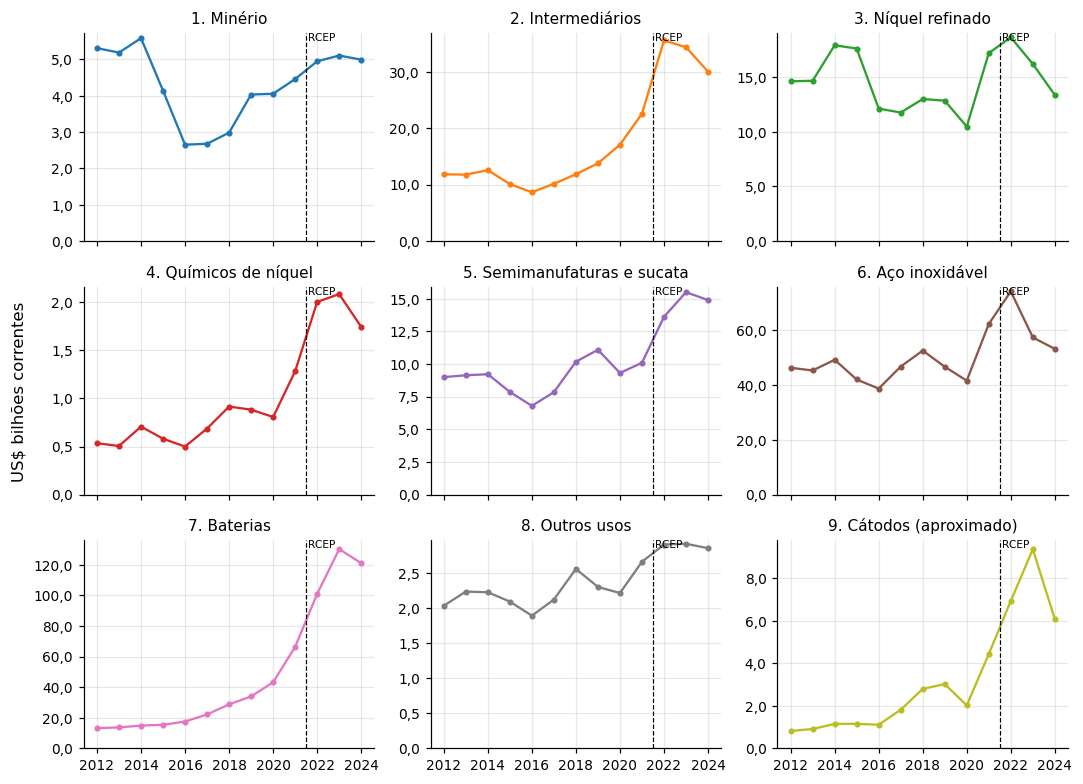

In [8]:
tab_volumes = (tot_sh6.assign(elo=tot_sh6["sh6"].map(cfg.SH6_ELO), produto=tot_sh6["sh6"].map(cfg.SH6_ROTULO))
               [["elo", "sh6", "produto", "ano", "valor", "qtd", "valor_unit", "cobertura_qtd", "n_fluxos"]])
salvar_tabela(tab_volumes, "t01_volumes_anuais_sh6")
salvar_tabela(tot_elo, "t02_volumes_anuais_elo")
fig = gr.valor_por_elo(tot_elo)

## Passo 4. Principais exportadores e importadores

### Tratamento
Participação de cada país no comércio mundial de cada produto (`share` = valor do país ÷ soma de todos
os fluxos do produto no ano), pelos lados exportador e importador, por SH6 e por elo. Como o BACI
reconcilia as duas declarações, exportações e importações mundiais têm o mesmo total. Concentração
medida pelo HHI (0–10.000), CR1 e CR4.

In [9]:
part_pais = {(lado, nivel): ind.participacoes(df, lado, nivel, "pais")
             for lado in ("exp", "imp") for nivel in ("sh6", "elo")}
conc = pd.concat({(lado, nivel): ind.concentracao(part_pais[(lado, nivel)], nivel)
                  for lado in ("exp", "imp") for nivel in ("sh6", "elo")}, names=["lado", "nivel_agreg", "i"]).reset_index(level=[0, 1])
part_pais[("exp", "sh6")].query("sh6 == '720260' and ano == 2024").nlargest(5, "share")

,ano,sh6,pais,valor,share
55892,2024,720260,idn,1.338040e+10,0.833628
55905,2024,720260,ncl,6.896685e+08,0.042968
55877,2024,720260,bra,6.001268e+08,0.037389
55881,2024,720260,col,5.683076e+08,0.035407
55900,2024,720260,kor,2.839801e+08,0.017693


### Validação
1. As participações somam 1 em cada ano × produto, nos dois lados e nos dois níveis.
2. Exportações e importações mundiais têm o mesmo total.
3. Recálculo manual, direto dos fluxos, da participação das Filipinas nas exportações de minério
   (260400) em 2024.
4. Os principais cinco somados a "Outros" dão 100%.

In [10]:
for (lado, nivel), p in part_pais.items():
    print(" ", lado, nivel, ind.checar_shares(p, nivel))

tot_exp = part_pais[("exp", "sh6")].groupby(["ano", "sh6"])["valor"].sum()
tot_imp = part_pais[("imp", "sh6")].groupby(["ano", "sh6"])["valor"].sum()
assert np.allclose(tot_exp, tot_imp)
ok("total mundial pelo lado exportador = total pelo lado importador")

f = df[(df["sh6"] == "260400") & (df["ano"] == 2024)]
manual = f.loc[f["exp"] == "phl", "valor"].sum() / f["valor"].sum()
funcao = part_pais[("exp", "sh6")].query("sh6 == '260400' and ano == 2024 and pais == 'phl'")["share"].item()
assert np.isclose(manual, funcao)
ok(f"Filipinas, minério, 2024: manual {manual:.6f} = função {funcao:.6f}")

w = ind.principais(part_pais[("exp", "sh6")], "260400", "sh6")
assert np.allclose(w.sum(axis=1), 1)
ok("principais + Outros = 100% em todos os anos")

  exp sh6 OK: 767 combinações ano×sh6, soma das participações entre 1.000000000000 e 1.000000000000
  exp elo OK: 117 combinações ano×elo, soma das participações entre 1.000000000000 e 1.000000000000
  imp sh6 OK: 767 combinações ano×sh6, soma das participações entre 1.000000000000 e 1.000000000000
  imp elo OK: 117 combinações ano×elo, soma das participações entre 1.000000000000 e 1.000000000000
✔ total mundial pelo lado exportador = total pelo lado importador
✔ Filipinas, minério, 2024: manual 0.399350 = função 0.399350
✔ principais + Outros = 100% em todos os anos


### Saídas do passo 4
Tabela dos dez maiores exportadores e importadores de cada produto em anos de referência (2012, 2019,
último ano pré-pandemia, 2021, último ano antes da RCEP, e 2024), e a série completa de concentração.

In [11]:
linhas = []
for (lado, nivel), p in part_pais.items():
    for ano in (2012, 2019, 2021, 2024):
        top = (p[p["ano"] == ano].sort_values("share", ascending=False).groupby(nivel).head(10)
               .assign(lado=lado, nivel_agreg=nivel, posicao=lambda d: d.groupby(nivel).cumcount() + 1))
        linhas.append(top.rename(columns={nivel: "produto_cod"}))
tab_top = pd.concat(linhas, ignore_index=True)
tab_top["produto"] = np.where(tab_top["nivel_agreg"] == "sh6", tab_top["produto_cod"].map(cfg.SH6_ROTULO), tab_top["produto_cod"])
tab_top["pais_nome"] = tab_top["pais"].map(ind.nome)
tab_top = tab_top[["nivel_agreg", "produto_cod", "produto", "lado", "ano", "posicao", "pais", "pais_nome", "valor", "share"]]
salvar_tabela(tab_top, "t03_principais_paises")

conc_out = conc.copy()
conc_out["produto_cod"] = conc_out["sh6"].fillna(conc_out["elo"])
salvar_tabela(conc_out[["nivel_agreg", "produto_cod", "lado", "ano", "hhi", "cr1", "cr4"]], "t04_concentracao")

tabela salva: outputs/tabelas/t03_principais_paises.csv (5431 linhas)
tabela salva: outputs/tabelas/t04_concentracao.csv (1768 linhas)


## Passo 5. Participação das macrorregiões

### Tratamento
Mesmo cálculo do passo 4, agregando os países por macrorregião do exportador e do importador.

In [12]:
part_reg = {(lado, nivel): ind.participacoes(df, lado, nivel, "regiao")
            for lado in ("exp", "imp") for nivel in ("sh6", "elo")}
part_reg[("exp", "elo")].query("elo == '2. Intermediários' and ano in (2012, 2024)").pivot(index="regiao", columns="ano", values="share").round(3)

ano,2012,2024
regiao,,
América Latina e Caribe,0.196,0.045
América do Norte,0.230,0.046
Europa,0.148,0.070
Oceania,0.161,0.060
Sudeste Asiático,0.166,0.724
Sul da Ásia,0.000,0.001
África,0.035,0.034
Ásia Ocidental e Central,0.000,0.004
Ásia Oriental,0.063,0.015


### Validação
1. Participações regionais somam 1.
2. A soma das participações dos países de uma região reproduz a participação da região (caso testado:
   Sudeste Asiático nas exportações de ferroníquel/NPI, todos os anos).

In [13]:
for (lado, nivel), p in part_reg.items():
    print(" ", lado, nivel, ind.checar_shares(p, nivel))

sea = paises.loc[paises["macrorregiao"] == "Sudeste Asiático", "iso3"]
pelos_paises = part_pais[("exp", "sh6")].query("sh6 == '720260'").loc[lambda d: d["pais"].isin(sea)].groupby("ano")["share"].sum()
pela_regiao = part_reg[("exp", "sh6")].query("sh6 == '720260' and regiao == 'Sudeste Asiático'").set_index("ano")["share"]
assert np.allclose(pelos_paises.reindex(pela_regiao.index), pela_regiao)
ok("Sudeste Asiático, 720260: soma dos países = participação regional em todos os anos")

  exp sh6 OK: 767 combinações ano×sh6, soma das participações entre 1.000000000000 e 1.000000000000
  exp elo OK: 117 combinações ano×elo, soma das participações entre 1.000000000000 e 1.000000000000
  imp sh6 OK: 767 combinações ano×sh6, soma das participações entre 1.000000000000 e 1.000000000000
  imp elo OK: 117 combinações ano×elo, soma das participações entre 1.000000000000 e 1.000000000000
✔ Sudeste Asiático, 720260: soma dos países = participação regional em todos os anos


In [14]:
tab_reg = pd.concat([p.rename(columns={nivel: "produto_cod"}).assign(lado=lado, nivel_agreg=nivel)
                     for (lado, nivel), p in part_reg.items()], ignore_index=True)
salvar_tabela(tab_reg[["nivel_agreg", "produto_cod", "lado", "ano", "regiao", "valor", "share"]], "t05_participacao_regioes")

tabela salva: outputs/tabelas/t05_participacao_regioes.csv (15884 linhas)


## Passo 6. Membros da RCEP antes e depois da adesão

### Tratamento
Para cada membro, a participação média nas exportações e importações mundiais de cada produto antes e
depois da entrada em vigor do acordo **para aquele membro** (`config.RCEP_VIGENCIA`). O ano de entrada
conta como primeiro ano posterior: 2022 para dez membros e também para Coreia do Sul (fevereiro) e
Malásia (março); 2023 para Indonésia (janeiro) e Filipinas (junho, ano parcial). Mianmar, com vigência
contestada, fica de fora.

Duas janelas:
- **completa**: todos os anos anteriores disponíveis (2012 até o ano anterior à entrada);
- **simétrica**: antes, o mesmo número de anos do período posterior (três anos para os que entraram em
  2022, dois para Indonésia e Filipinas). É a comparação principal, pois a janela completa mistura
  mudanças estruturais da década de 2010 (como as proibições de exportação de minério da Indonésia).

Anos sem comércio do membro entram com participação zero (painel balanceado).

In [15]:
ad = {(lado, nivel, janela): ind.antes_depois(part_pais[(lado, nivel)], nivel, janela)
      for lado in ("exp", "imp") for nivel in ("sh6", "elo") for janela in ("completa", "simetrica")}
ad[("exp", "sh6", "simetrica")].query("sh6 == '720260'").sort_values("share_depois", ascending=False).round(4).head(6)

,sh6,pais,ano_entrada,share_antes,share_depois,valor_antes,valor_depois,var_pp,anos_antes,anos_depois,janela
87,720260,idn,2023,0.6467,0.8117,1.042688e+10,1.409625e+10,16.5082,2021–2022,2023–2024,simetrica
90,720260,kor,2022,0.0121,0.0141,1.101117e+08,2.515986e+08,0.2028,2019–2021,2022–2024,simetrica
88,720260,jpn,2022,0.0373,0.0055,3.237481e+08,1.054115e+08,-3.1778,2019–2021,2022–2024,simetrica
92,720260,mys,2022,0.0015,0.0016,1.788010e+07,2.709640e+07,0.0066,2019–2021,2022–2024,simetrica
86,720260,chn,2022,0.0006,0.0008,4.336257e+06,1.458342e+07,0.0280,2019–2021,2022–2024,simetrica
95,720260,sgp,2022,0.0030,0.0003,2.553549e+07,6.358735e+06,-0.2642,2019–2021,2022–2024,simetrica


### Validação
1. Painel balanceado: anos × produtos × 15 membros, sem buracos.
2. Mianmar ausente; 14 membros em cada produto.
3. Períodos corretos por membro (Indonésia: simétrica 2021–2022 vs. 2023–2024; China: 2019–2021 vs.
   2022–2024; completa começa em 2012).
4. Recálculo manual da média antes/depois da Indonésia nas exportações de ferroníquel/NPI (720260),
   nas duas janelas, inclusive com anos de valor zero.

In [16]:
painel = ind.painel_rcep(part_pais[("exp", "sh6")], "sh6")
assert len(painel) == len(cfg.ANOS) * len(cfg.TODOS_SH6) * 15 and not painel.duplicated(["ano", "sh6", "pais"]).any()
ok(f"painel balanceado: {len(painel):,} linhas = {len(cfg.ANOS)} anos × {len(cfg.TODOS_SH6)} SH6 × 15 membros")

for chave, r in ad.items():
    assert "mmr" not in set(r["pais"]) and (r.groupby(r.columns[0])["pais"].nunique() == 14).all(), chave
ok("Mianmar excluído; 14 membros por produto em todas as tabelas")

s = ad[("exp", "sh6", "simetrica")].set_index(["sh6", "pais"])
c = ad[("exp", "sh6", "completa")].set_index(["sh6", "pais"])
assert s.loc[("720260", "idn"), ["anos_antes", "anos_depois"]].tolist() == ["2021–2022", "2023–2024"]
assert s.loc[("720260", "chn"), ["anos_antes", "anos_depois"]].tolist() == ["2019–2021", "2022–2024"]
assert c.loc[("720260", "idn"), "anos_antes"] == "2012–2022"
ok("períodos antes/depois corretos por membro")

serie = painel.query("sh6 == '720260' and pais == 'idn'").set_index("ano")["share"]
manual = {"simetrica": (serie.loc[2021:2022].mean(), serie.loc[2023:2024].mean()),
          "completa": (serie.loc[2012:2022].mean(), serie.loc[2023:2024].mean())}
for janela, (antes, depois) in manual.items():
    r = ad[("exp", "sh6", janela)].set_index(["sh6", "pais"]).loc[("720260", "idn")]
    assert np.isclose(r["share_antes"], antes) and np.isclose(r["share_depois"], depois)
    ok(f"Indonésia, 720260, janela {janela}: antes {antes:.4f}, depois {depois:.4f} (manual = função)")

✔ painel balanceado: 11,505 linhas = 13 anos × 59 SH6 × 15 membros
✔ Mianmar excluído; 14 membros por produto em todas as tabelas
✔ períodos antes/depois corretos por membro
✔ Indonésia, 720260, janela simetrica: antes 0.6467, depois 0.8117 (manual = função)
✔ Indonésia, 720260, janela completa: antes 0.3010, depois 0.8117 (manual = função)


### Saídas do passo 6
Figuras: participação antes/depois (janela simétrica) para os SH6 do núcleo e para os elos, nas
exportações e nas importações. A tabela traz as duas janelas para todos os produtos.

tabela salva: outputs/tabelas/t06_rcep_antes_depois.csv (3808 linhas)


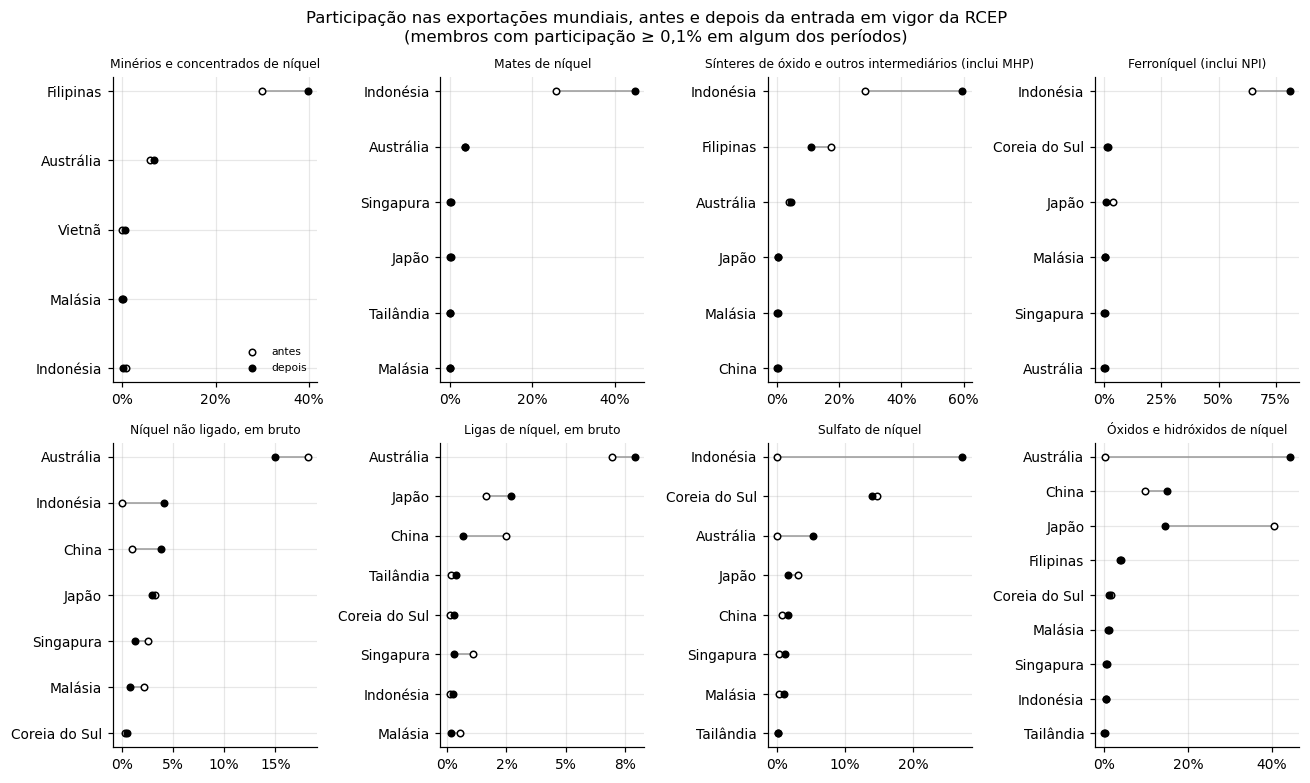

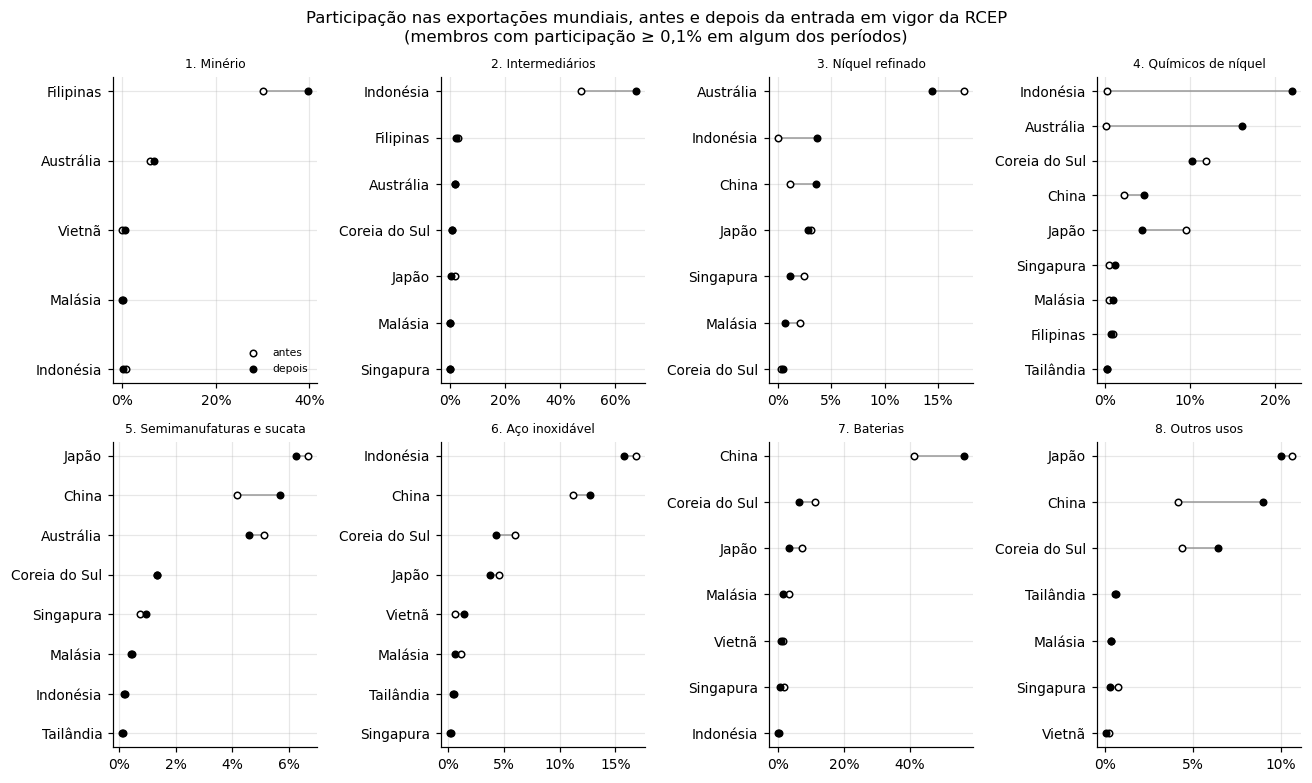

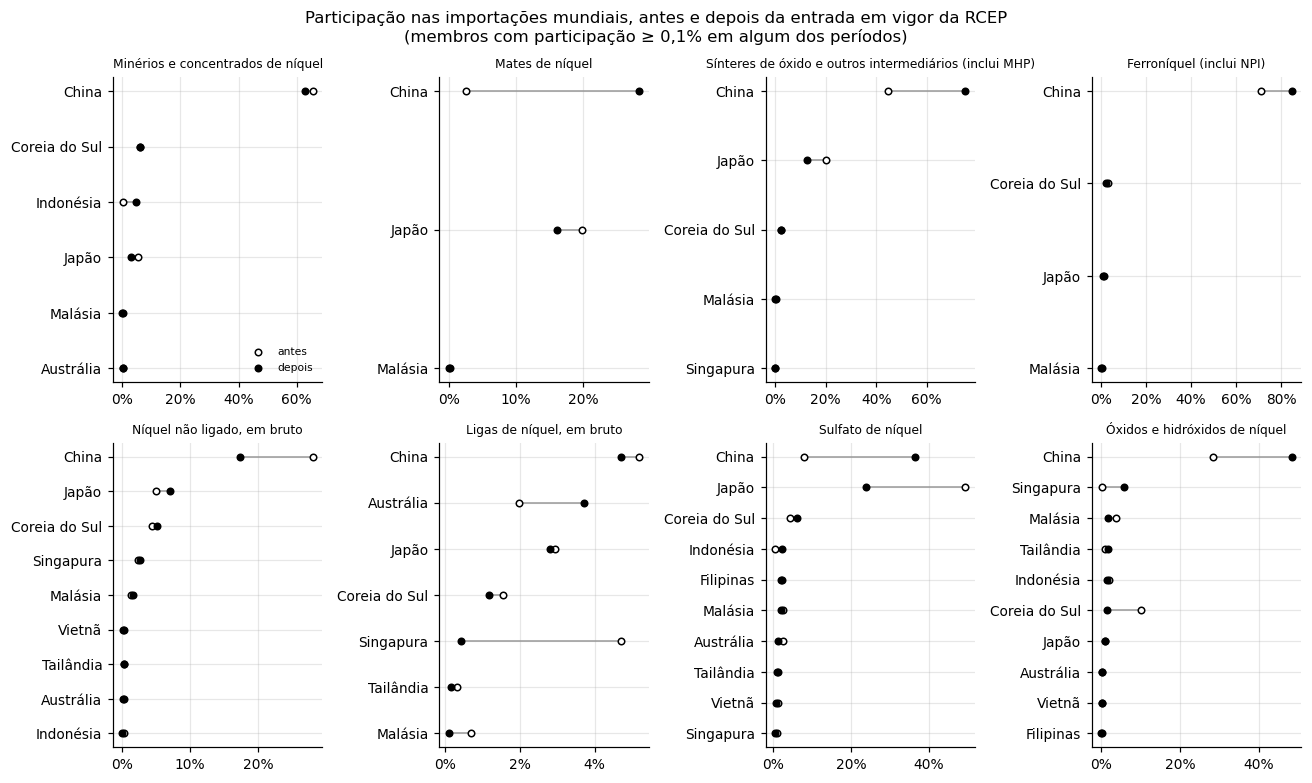

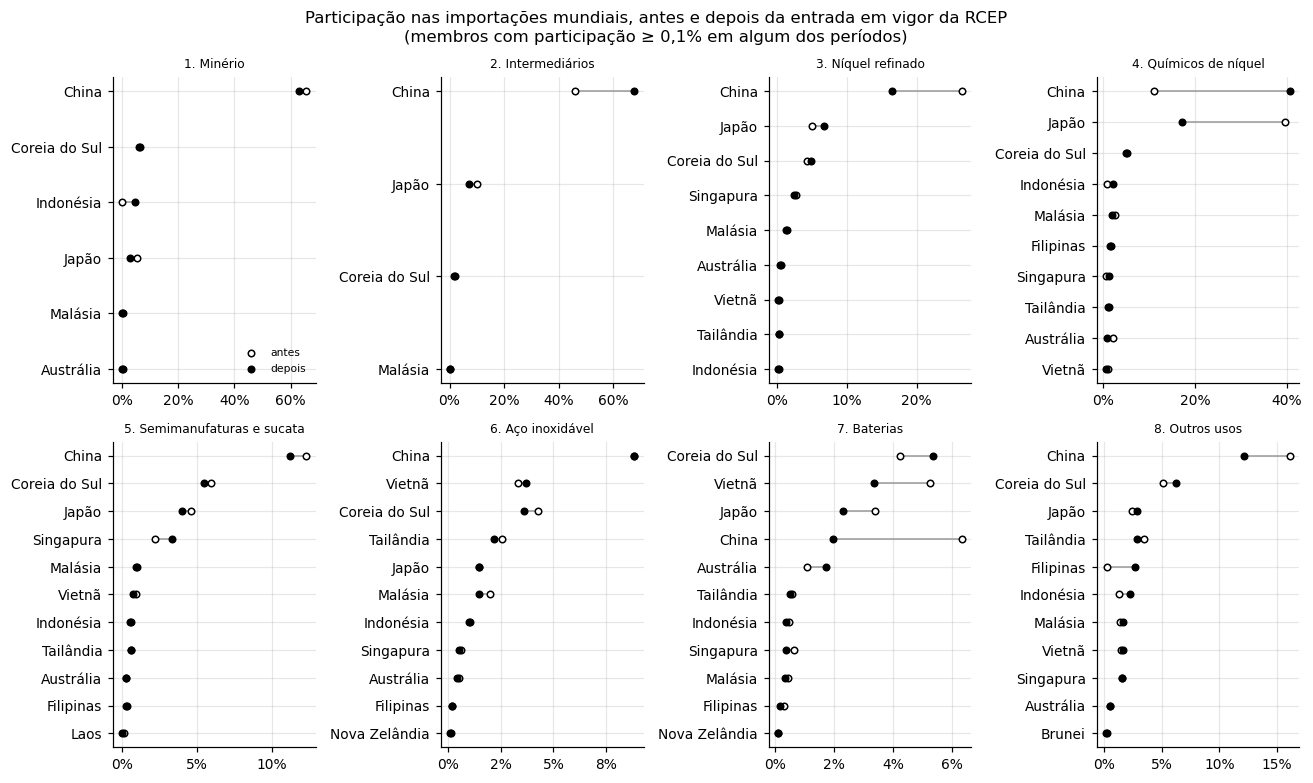

In [17]:
tab_ad = pd.concat([r.rename(columns={r.columns[0]: "produto_cod"}).assign(lado=lado, nivel_agreg=nivel)
                    for (lado, nivel, janela), r in ad.items()], ignore_index=True)
tab_ad["pais_nome"] = tab_ad["pais"].map(ind.nome)
salvar_tabela(tab_ad[["nivel_agreg", "produto_cod", "lado", "janela", "pais", "pais_nome", "ano_entrada",
                      "anos_antes", "anos_depois", "share_antes", "share_depois", "var_pp", "valor_antes", "valor_depois"]],
              "t06_rcep_antes_depois")

elos_principais = [e for e in cfg.CADEIA if e not in cfg.ELOS_APROXIMADOS]
for lado, rot in (("exp", "exportações"), ("imp", "importações")):
    gr.antes_depois_membros(ad[(lado, "sh6", "simetrica")], "sh6", cfg.SH6_NUCLEO, rot, f"fig02_rcep_antes_depois_{lado}_sh6_nucleo")
    gr.antes_depois_membros(ad[(lado, "elo", "simetrica")], "elo", elos_principais, rot, f"fig03_rcep_antes_depois_{lado}_elos")

## Passo 7. Comércio intra-RCEP e divisão regional

### Tratamento
(a) Por ano e produto, a parcela do comércio mundial realizada entre membros da RCEP e a parcela das
exportações dos membros que se destina a outros membros. (b) Matriz de fluxos entre China, ASEAN,
demais membros da RCEP e resto do mundo, como parcela do comércio mundial do produto, nos três anos
anteriores (2019–2021) e nos três posteriores (2022–2024) à entrada em vigor.

In [18]:
intra = {nivel: ind.intra_rcep(df, nivel) for nivel in ("sh6", "elo")}
periodos = {"2019–2021": [2019, 2020, 2021], "2022–2024": [2022, 2023, 2024]}
matrizes = {(nivel, cod, per): ind.matriz_grupos(df, nivel, cod, anos)
            for nivel, cods in (("sh6", cfg.SH6_NUCLEO), ("elo", elos_principais))
            for cod in cods for per, anos in periodos.items()}
pd.concat({per: matrizes[("sh6", "720260", per)] for per in periodos}, axis=1).round(3)

2019–2021                                   2022–2024                                  
grupo_imp          China  ASEAN Demais RCEP Resto do mundo     China  ASEAN Demais RCEP Resto do mundo
grupo_exp                                                                                             
China              0.000  0.000       0.000          0.000     0.000  0.000       0.000          0.001
ASEAN              0.506  0.000       0.010          0.039     0.743  0.000       0.008          0.025
Demais RCEP        0.026  0.000       0.004          0.017     0.016  0.000       0.001          0.003
Resto do mundo     0.185  0.005       0.024          0.183     0.088  0.002       0.021          0.092

### Validação
1. Cada matriz soma 1, e o fluxo resto do mundo → resto do mundo é o complemento dos demais.
2. O comércio intra-RCEP nunca excede o comércio mundial nem as exportações dos membros.
3. Recálculo manual da parcela intra-RCEP do minério (260400) em 2024.

In [19]:
for k, m in matrizes.items():
    assert np.isclose(m.values.sum(), 1), k
ok(f"{len(matrizes)} matrizes somam 1")

for nivel, t in intra.items():
    assert (t["valor_intra"] <= t["valor_mundo"] + 1e-6).all() and (t["valor_intra"] <= t["valor_exp_rcep"] + 1e-6).all()
ok("intra-RCEP ≤ mundo e ≤ exportações dos membros")

f = df[(df["sh6"] == "260400") & (df["ano"] == 2024)]
manual = f.loc[f["exp"].isin(cfg.RCEP) & f["imp"].isin(cfg.RCEP), "valor"].sum() / f["valor"].sum()
funcao = intra["sh6"].query("sh6 == '260400' and ano == 2024")["intra_no_mundo"].item()
assert np.isclose(manual, funcao)
ok(f"minério, 2024: parcela intra-RCEP manual {manual:.4f} = função {funcao:.4f}")

✔ 32 matrizes somam 1
✔ intra-RCEP ≤ mundo e ≤ exportações dos membros
✔ minério, 2024: parcela intra-RCEP manual 0.4494 = função 0.4494


tabela salva: outputs/tabelas/t07_intra_rcep.csv (884 linhas)
tabela salva: outputs/tabelas/t08_matriz_grupos.csv (512 linhas)


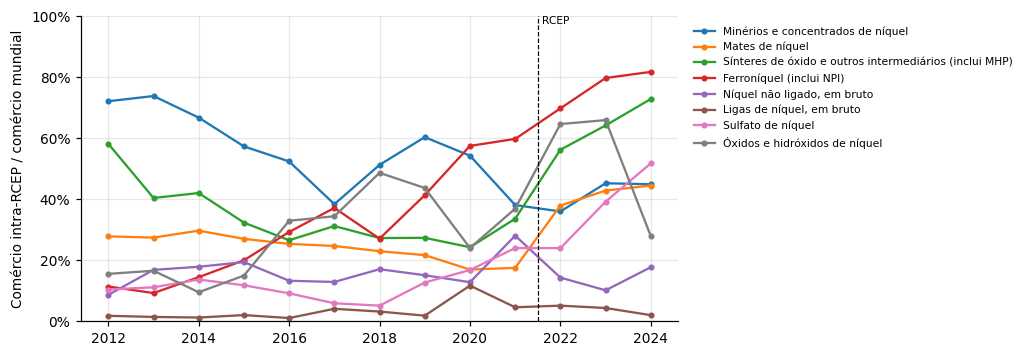

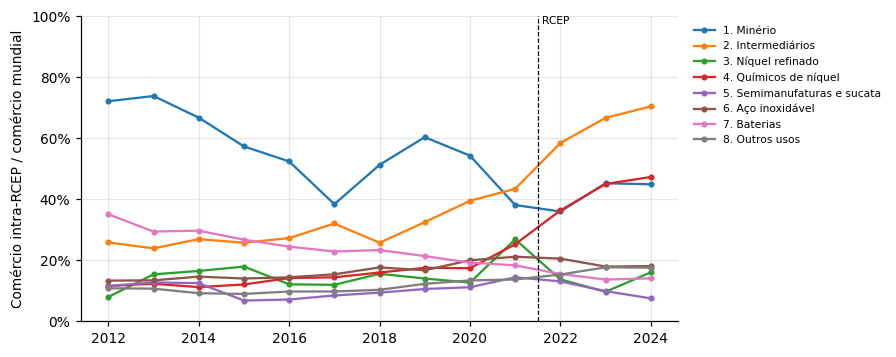

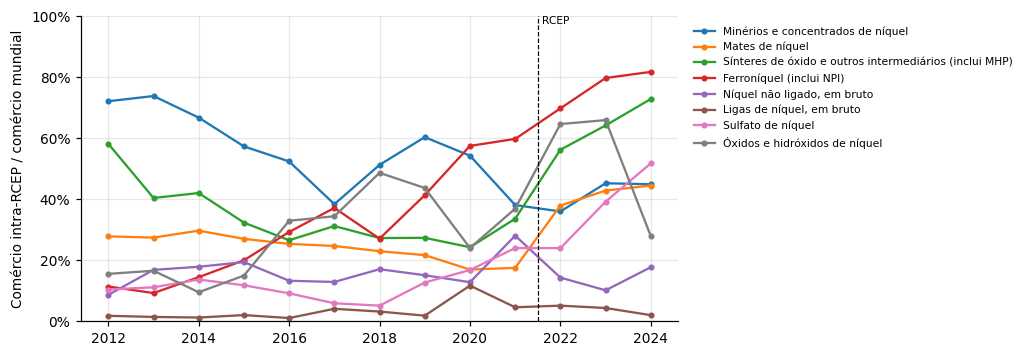

In [20]:
tab_intra = pd.concat([t.rename(columns={nivel: "produto_cod"}).assign(nivel_agreg=nivel) for nivel, t in intra.items()], ignore_index=True)
salvar_tabela(tab_intra[["nivel_agreg", "produto_cod", "ano", "valor_mundo", "valor_intra", "valor_exp_rcep",
                         "intra_no_mundo", "intra_nas_exp_rcep"]], "t07_intra_rcep")

tab_matriz = pd.concat([m.stack().rename("share").reset_index().assign(nivel_agreg=nivel, produto_cod=cod, periodo=per)
                        for (nivel, cod, per), m in matrizes.items()], ignore_index=True)
salvar_tabela(tab_matriz[["nivel_agreg", "produto_cod", "periodo", "grupo_exp", "grupo_imp", "share"]], "t08_matriz_grupos")

gr.intra_rcep(intra["elo"], "elo", elos_principais, "fig04_intra_rcep_elos")
gr.intra_rcep(intra["sh6"], "sh6", cfg.SH6_NUCLEO, "fig05_intra_rcep_sh6_nucleo")

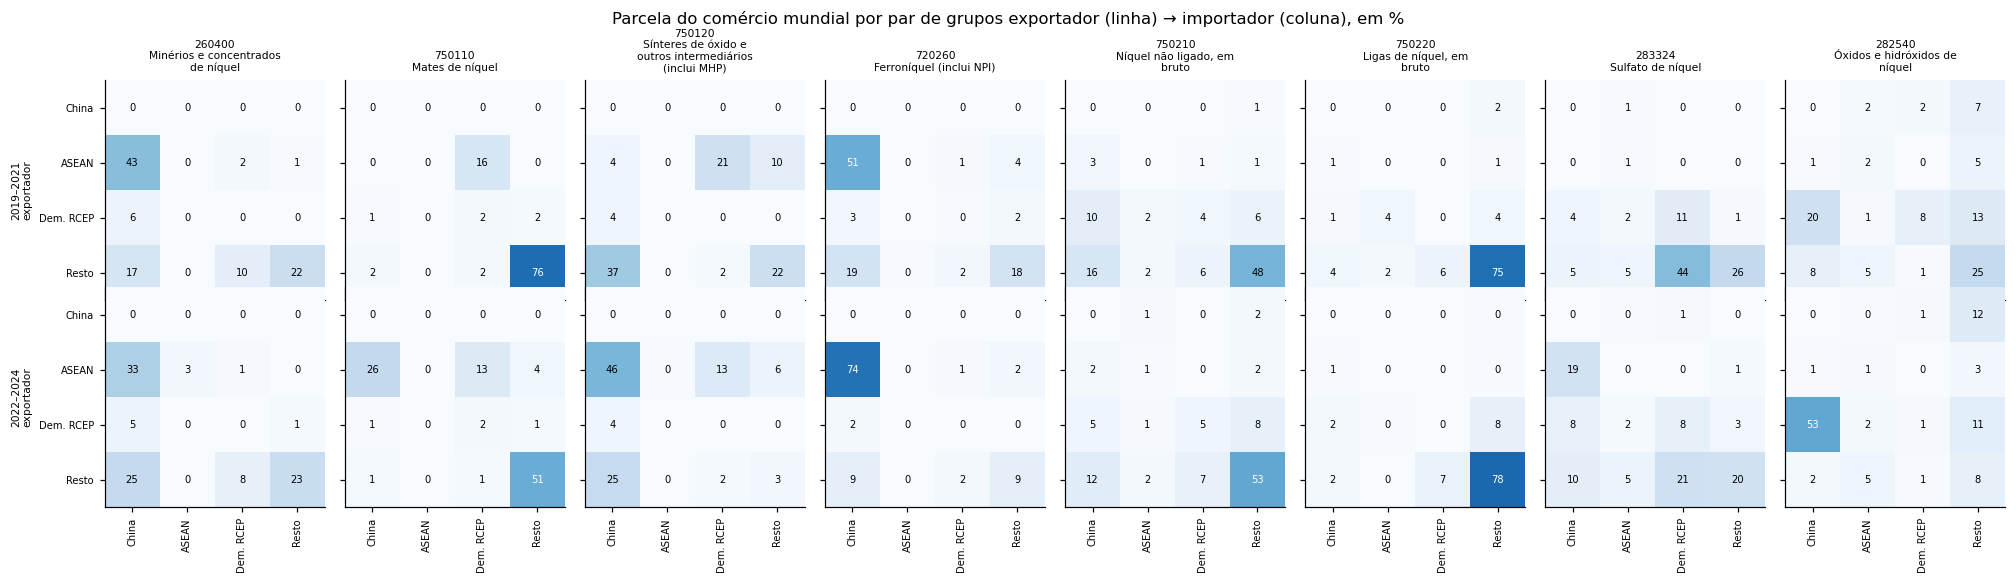

In [21]:
# Figura das matrizes: um painel por SH6 do núcleo, antes e depois
fig, axs = plt.subplots(2, len(cfg.SH6_NUCLEO), figsize=(2.3 * len(cfg.SH6_NUCLEO), 5.2))
rot_curto = ["China", "ASEAN", "Dem. RCEP", "Resto"]
for j, cod in enumerate(cfg.SH6_NUCLEO):
    for i, per in enumerate(periodos):
        m = matrizes[("sh6", cod, per)]
        ax = axs[i, j]
        ax.imshow(m.values, cmap="Blues", vmin=0, vmax=1)
        for a in range(4):
            for b in range(4):
                v = m.values[a, b]
                ax.text(b, a, f"{v * 100:.0f}", ha="center", va="center", fontsize=6.5, color="white" if v > 0.5 else "black")
        ax.set_xticks(range(4), rot_curto if i == 1 else [], rotation=90, fontsize=6.5)
        ax.set_yticks(range(4), rot_curto if j == 0 else [], fontsize=6.5)
        ax.grid(False)
        if i == 0:
            ax.set_title(f"{cod}\n" + textwrap.fill(cfg.SH6_ROTULO[cod], 24), fontsize=7)
    axs[0, 0].set_ylabel("2019–2021\nexportador", fontsize=7)
    axs[1, 0].set_ylabel("2022–2024\nexportador", fontsize=7)
fig.suptitle("Parcela do comércio mundial por par de grupos exportador (linha) → importador (coluna), em %")
fig.tight_layout()
gr.salvar(fig, "fig06_matriz_grupos_sh6_nucleo",
          tab_matriz.query("nivel_agreg == 'sh6'").pivot_table(index=["produto_cod", "periodo", "grupo_exp"], columns="grupo_imp", values="share"))

## Passo 8. Painéis replicados por produto

### Tratamento
Para cada SH6 do núcleo e para cada elo (inclusive o aproximado), o mesmo conjunto de painéis:
(a) valor e quantidade do comércio mundial; (b) principais exportadores; (c) principais importadores;
(d) e (e) participação das macrorregiões nas exportações e importações. Os principais países são os
cinco maiores pelo valor acumulado 2012–2024.

17 painéis gerados


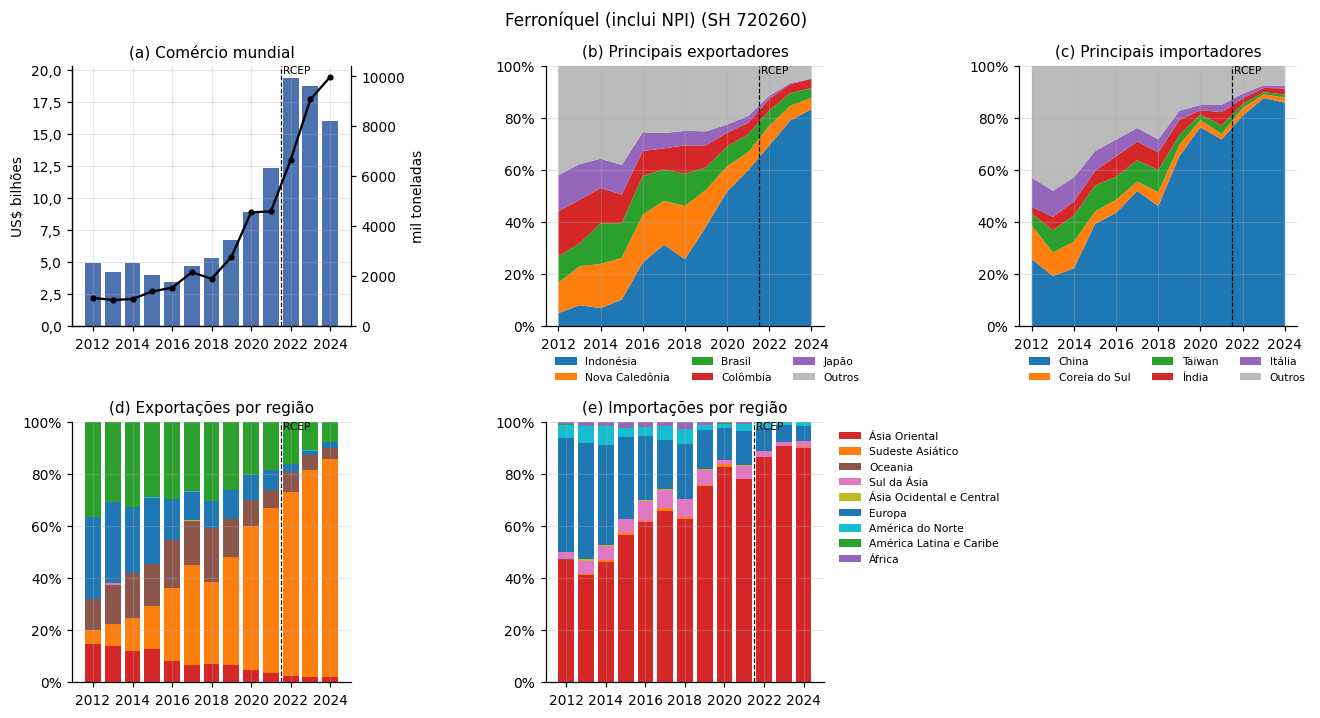

In [22]:
part_pais_lado = {nivel: {lado: part_pais[(lado, nivel)] for lado in ("exp", "imp")} for nivel in ("sh6", "elo")}
part_reg_lado = {nivel: {lado: part_reg[(lado, nivel)] for lado in ("exp", "imp")} for nivel in ("sh6", "elo")}
tot = {"sh6": tot_sh6, "elo": tot_elo}
paineis = [("sh6", c) for c in cfg.SH6_NUCLEO] + [("elo", e) for e in cfg.CADEIA]
for nivel, cod in paineis:
    fig = gr.painel_produto(tot[nivel], part_pais_lado[nivel], part_reg_lado[nivel], cod, nivel)
    if not (nivel == "sh6" and cod == "720260"):
        plt.close(fig)  # mostra só um exemplo no notebook; todos ficam em outputs/figuras
print(f"{len(paineis)} painéis gerados")

### Validação
Os dados gravados com cada painel são relidos e conferidos contra as tabelas do passo 3 (valor total) e
do passo 4 (participação do principal exportador).

In [23]:
for nivel, cod in paineis:
    arq = cfg.DIR_TAB / "dados_figuras" / f"painel_{gr.nome_produto(cod, nivel)}.csv"
    d = pd.read_csv(arq, header=[0, 1], index_col=0, encoding="utf-8-sig")
    esperado = tot[nivel].query(f"{nivel} == @cod").set_index("ano")["valor"]
    assert np.allclose(d[("total", "valor")].values, esperado.reindex(cfg.ANOS).values), (nivel, cod)
    w = ind.principais(part_pais[("exp", nivel)], cod, nivel)
    assert np.allclose(d["exportadores"].iloc[:, 0].values, w.iloc[:, 0].values), (nivel, cod)
ok(f"{len(paineis)} painéis: dados gravados conferem com os passos 3 e 4")

✔ 17 painéis: dados gravados conferem com os passos 3 e 4


## Passo 9. Mapas do comércio mundial

### Tratamento
Para cada SH6 do núcleo e cada elo, dois mapas:

- **participação**: parcela de cada país nas exportações e nas importações mundiais, somando os três
  anos anteriores (2019–2021) e os três posteriores (2022–2024) à vigência da RCEP, em classes fixas;
- **fluxos**: os 20 maiores fluxos bilaterais (média anual de cada período), com espessura proporcional
  ao valor na mesma escala nos dois painéis e cor pelo grupo do exportador.

Base cartográfica Natural Earth 1:50m (domínio público), projeção Robinson, versionada em
`data/referencia/mundo_natural_earth_50m.geojson` (gerada por `mapas.preparar_base()` a partir de
`mapas.URL_NE`).

34 mapas gerados


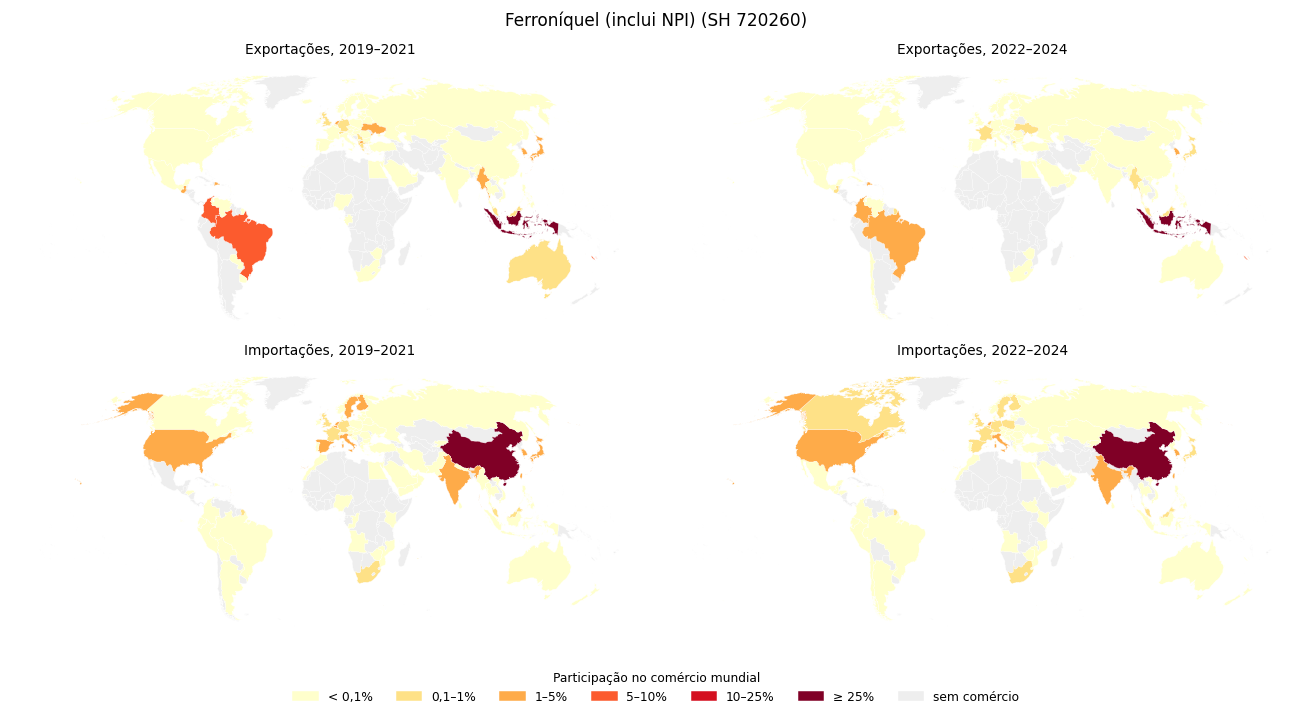

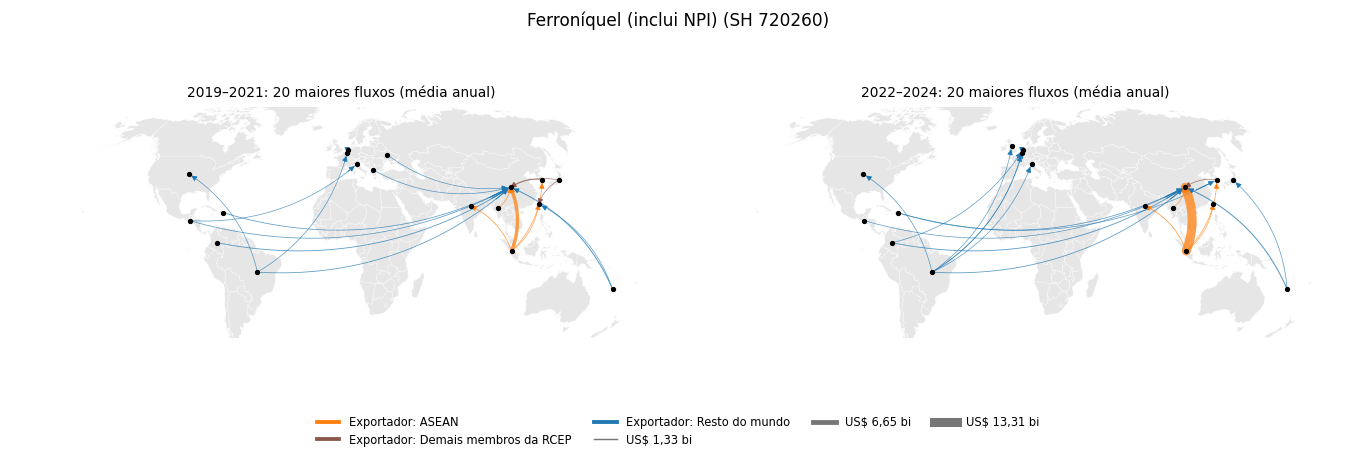

In [24]:
base_mapa = mp.carregar_base()
for nivel, cod in paineis:
    for funcao in (mp.mapa_participacao, mp.mapa_fluxos):
        fig = funcao(df, base_mapa, nivel, cod, periodos)
        if not (nivel == "sh6" and cod == "720260"):
            plt.close(fig)
print(f"{2 * len(paineis)} mapas gerados")

### Validação
1. Economias da base sem geometria no mapa e sua maior participação em qualquer produto e ano
   (precisa ser desprezível, pois elas não aparecem no mapa).
2. As participações gravadas com cada mapa somam 100% em cada painel.
3. Os fluxos gravados no mapa do ferroníquel (2022–2024) coincidem com os 20 maiores calculados
   diretamente dos fluxos.

In [25]:
sem_geo = sorted(set(paises["iso3"]) - set(base_mapa["iso3"]))
maior = max(part_pais[(lado, nivel)].query("pais in @sem_geo")["share"].max() for lado in ("exp", "imp") for nivel in ("sh6", "elo"))
print("Sem geometria:", [ind.nome(c) for c in sem_geo])
assert maior < 0.005, maior
ok(f"maior participação anual de uma economia sem geometria: {maior:.5f} (< 0,5%)")

for nivel, cod in paineis:
    t = pd.read_csv(cfg.DIR_TAB / "dados_figuras" / f"mapa_participacao_{gr.nome_produto(cod, nivel)}.csv", index_col=0, encoding="utf-8-sig")
    somas = t.drop(columns="pais").sum()
    assert np.allclose(somas, 1), (cod, somas)
ok(f"{len(paineis)} mapas de participação: cada painel soma 100%")

t = pd.read_csv(cfg.DIR_TAB / "dados_figuras" / "mapa_fluxos_sh6_720260.csv", index_col=0, encoding="utf-8-sig")["2022–2024"].dropna()
direto = (df[(df["sh6"] == "720260") & df["ano"].isin(periodos["2022–2024"])].groupby(["exp", "imp"])["valor"].sum() / 3).nlargest(20)
assert np.allclose(np.sort(t.values), np.sort(direto.values))
ok("mapa de fluxos do 720260 (2022–2024) = 20 maiores fluxos calculados diretamente")

Sem geometria: ['Bonaire', 'Ilhas Cocos (Keeling)', 'Ilha Christmas', 'Gibraltar', 'Mayotte', 'Tokelau']
✔ maior participação anual de uma economia sem geometria: 0.00110 (< 0,5%)
✔ 17 mapas de participação: cada painel soma 100%
✔ mapa de fluxos do 720260 (2022–2024) = 20 maiores fluxos calculados diretamente


## Passo 10. Composição dos parceiros e volume dos membros da RCEP

### Tratamento
Para cada membro com data de vigência, cada produto e cada sentido (exportações por destino,
importações por origem), comparação entre a janela simétrica anterior e a posterior à adesão:

- **volume**: média anual do valor (US$ correntes) e, por SH6, da quantidade (t); variação percentual,
  ao lado da variação do comércio mundial do mesmo produto nas mesmas janelas;
- **composição dos parceiros**: número de parceiros, HHI dos parceiros, principal parceiro e sua
  parcela, parcelas da China, da ASEAN e do conjunto da RCEP;
- **índice de dissimilaridade** D = ½ Σ |parcela depois − parcela antes|, de 0 (mesmos parceiros, nas
  mesmas proporções) a 1 (nenhum parceiro em comum);
- **placebos**: o mesmo D para todas as janelas de igual comprimento anteriores à vigência (5 pares para
  quem entrou em 2022, 8 para Indonésia e Filipinas). D acima de todos os placebos indica uma
  recomposição maior que qualquer uma observada antes; não identifica a causa.

As figuras mostram apenas os pares membro × produto com comércio médio de pelo menos US$ 10 milhões
por ano em uma das janelas (`parceiros.LIMIAR_RELEVANCIA_USD`); as tabelas trazem todos.

In [26]:
res_parc = {(lado, nivel): pa.resumo(df, nivel, lado) for lado in ("exp", "imp") for nivel in ("sh6", "elo")}
comp_parc = {(lado, nivel): pa.composicao(df, nivel, lado) for lado in ("exp", "imp") for nivel in ("sh6", "elo")}
print("Janelas placebo para quem entrou em 2022:", [f"{a[0]}–{a[-1]} × {b[0]}–{b[-1]}" for a, b in pa.janelas_placebo(2022)])
cols = ["membro", "sh6", "valor_medio_antes", "valor_medio_depois", "var_valor_pct", "var_qtd_pct", "var_valor_mundo_pct",
        "principal_antes", "principal_depois", "share_china_antes", "share_china_depois", "indice_mudanca", "placebo_max", "acima_placebos"]
res_parc[("exp", "sh6")].query("relevante and sh6 in @cfg.SH6_NUCLEO")[cols].round(3)

Janelas placebo para quem entrou em 2022: ['2012–2014 × 2015–2017', '2013–2015 × 2016–2018', '2014–2016 × 2017–2019', '2015–2017 × 2018–2020', '2016–2018 × 2019–2021']


,membro,sh6,valor_medio_antes,valor_medio_depois,var_valor_pct,var_qtd_pct,var_valor_mundo_pct,principal_antes,principal_depois,share_china_antes,share_china_depois,indice_mudanca,placebo_max,acima_placebos
0,aus,260400,2.414602e+08,3.440754e+08,4.249800e+01,-1.991100e+01,19.938,chn,chn,0.998,0.775,0.224,0.221,True
1,aus,282540,6.314427e+05,2.485975e+08,3.926977e+04,4.629886e+04,182.853,chn,chn,0.958,0.883,0.117,0.992,False
3,aus,283324,3.071887e+05,7.554673e+07,2.449294e+04,9.994522e+03,84.114,jpn,chn,0.096,0.581,0.882,0.998,False
38,aus,750110,1.924597e+08,3.299060e+08,7.141600e+01,3.361500e+01,76.058,jpn,jpn,0.138,0.207,0.069,0.647,False
39,aus,750120,1.393802e+08,2.657036e+08,9.063200e+01,5.233700e+01,86.652,chn,chn,0.980,0.949,0.046,0.321,False
40,aus,750210,2.371205e+09,2.272852e+09,-4.148000e+00,-3.833900e+01,17.842,chn,chn,0.486,0.247,0.316,0.522,False
41,aus,750220,6.968888e+07,1.055743e+08,5.149400e+01,-6.261000e+00,33.757,sgp,swe,0.077,0.062,0.539,0.543,False
127,chn,282540,1.697932e+07,6.317340e+07,2.720610e+02,2.241800e+02,182.853,swe,usa,0.000,0.000,0.636,0.589,True
129,chn,283324,5.351711e+06,2.418932e+07,3.519920e+02,3.560520e+02,84.114,vnm,kor,0.000,0.000,0.760,0.516,True
132,chn,720260,4.336257e+06,1.458342e+07,2.363130e+02,2.025600e+02,93.464,idn,gbr,0.000,0.000,0.713,0.828,False


### Validação
1. As parcelas dos parceiros somam 1 em cada membro × produto × período com comércio.
2. Recálculo manual, direto dos fluxos, do índice D das exportações de ferroníquel/NPI da Indonésia
   (2021–2022 × 2023–2024).
3. Número de placebos: no máximo 5 para quem entrou em 2022 e 8 para quem entrou em 2023, e pelo
   menos um sempre que o comércio é relevante nas duas janelas.
4. Coerência entre módulos: o valor médio antes/depois deste passo coincide com o do passo 6.
5. Parcela da RCEP ≥ parcela da China + parcela da ASEAN.

In [27]:
for (lado, nivel), c in comp_parc.items():
    for per in ("antes", "depois"):
        s = c.groupby(["membro", nivel])[f"share_{per}"].sum(min_count=1).dropna()
        s = s[s > 0]
        assert np.allclose(s, 1), (lado, nivel, per)
ok("parcelas dos parceiros somam 1 em todos os membros × produtos × períodos com comércio")

f = df[(df["sh6"] == "720260") & (df["exp"] == "idn")]
antes = f[f["ano"].isin([2021, 2022])].groupby("imp")["valor"].sum()
depois = f[f["ano"].isin([2023, 2024])].groupby("imp")["valor"].sum()
j = pd.concat([antes / antes.sum(), depois / depois.sum()], axis=1).fillna(0)
D_manual = 0.5 * (j.iloc[:, 1] - j.iloc[:, 0]).abs().sum()
D_funcao = res_parc[("exp", "sh6")].query("membro == 'idn' and sh6 == '720260'")["indice_mudanca"].item()
assert np.isclose(D_manual, D_funcao)
ok(f"Indonésia, 720260, exportações: D manual {D_manual:.4f} = função {D_funcao:.4f}")

for (lado, nivel), r in res_parc.items():
    com_d = r.dropna(subset=["indice_mudanca"])
    assert (com_d["placebo_n"] <= com_d["ano_entrada"].map({2022: 5, 2023: 8})).all()
    assert (r.query("valor_medio_antes > 1e7 and valor_medio_depois > 1e7")["placebo_n"] >= 1).all()
ok("número de placebos dentro do esperado (até 5 para 2022; até 8 para 2023)")

a6 = ad[("exp", "sh6", "simetrica")].set_index(["sh6", "pais"])
r10 = res_parc[("exp", "sh6")].set_index(["sh6", "membro"])
comum = r10.index.intersection(a6.index)
assert np.allclose(r10.loc[comum, "valor_medio_antes"], a6.loc[comum, "valor_antes"])
assert np.allclose(r10.loc[comum, "valor_medio_depois"], a6.loc[comum, "valor_depois"])
ok(f"valores médios antes/depois idênticos aos do passo 6 em {len(comum)} pares membro × SH6")

for r in res_parc.values():
    x = r.dropna(subset=["share_rcep_antes"])
    assert (x["share_rcep_antes"] + 1e-9 >= x["share_china_antes"] + x["share_asean_antes"]).all()
ok("parcela RCEP ≥ China + ASEAN")

✔ parcelas dos parceiros somam 1 em todos os membros × produtos × períodos com comércio
✔ Indonésia, 720260, exportações: D manual 0.0314 = função 0.0314
✔ número de placebos dentro do esperado (até 5 para 2022; até 8 para 2023)
✔ valores médios antes/depois idênticos aos do passo 6 em 743 pares membro × SH6
✔ parcela RCEP ≥ China + ASEAN


### Saídas do passo 10
Tabelas completas e figuras: índice de mudança dos parceiros (com marca dos casos acima dos placebos),
variação do valor e da quantidade, e composição dos parceiros antes e depois para o principal
exportador e o principal importador da RCEP em cada SH6 do núcleo (escolhidos pelo valor médio no
período posterior).

tabela salva: outputs/tabelas/t09_parceiros_volume_membros.csv (1802 linhas)


tabela salva: outputs/tabelas/t10_parceiros_composicao.csv (54894 linhas)


C:\Users\ailto\1.projetos\cadeia-niquel-rcep\src\niquel\graficos.py:195: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  rel = rel.fillna(False).astype(bool)


C:\Users\ailto\1.projetos\cadeia-niquel-rcep\src\niquel\graficos.py:195: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  rel = rel.fillna(False).astype(bool)


C:\Users\ailto\1.projetos\cadeia-niquel-rcep\src\niquel\graficos.py:195: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  rel = rel.fillna(False).astype(bool)


...

C:\Users\ailto\1.projetos\cadeia-niquel-rcep\src\niquel\graficos.py:195: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  rel = rel.fillna(False).astype(bool)


C:\Users\ailto\1.projetos\cadeia-niquel-rcep\src\niquel\graficos.py:195: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  rel = rel.fillna(False).astype(bool)


C:\Users\ailto\1.projetos\cadeia-niquel-rcep\src\niquel\graficos.py:195: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  rel = rel.fillna(False).astype(bool)


C:\Users\ailto\1.projetos\cadeia-niquel-rcep\src\niquel\graficos.py:195: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  rel = rel.fillna(False).astype(bool)


C:\Users\ailto\1.projetos\cadeia-niquel-rcep\src\niquel\graficos.py:195: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  rel = rel.fillna(False).astype(bool)


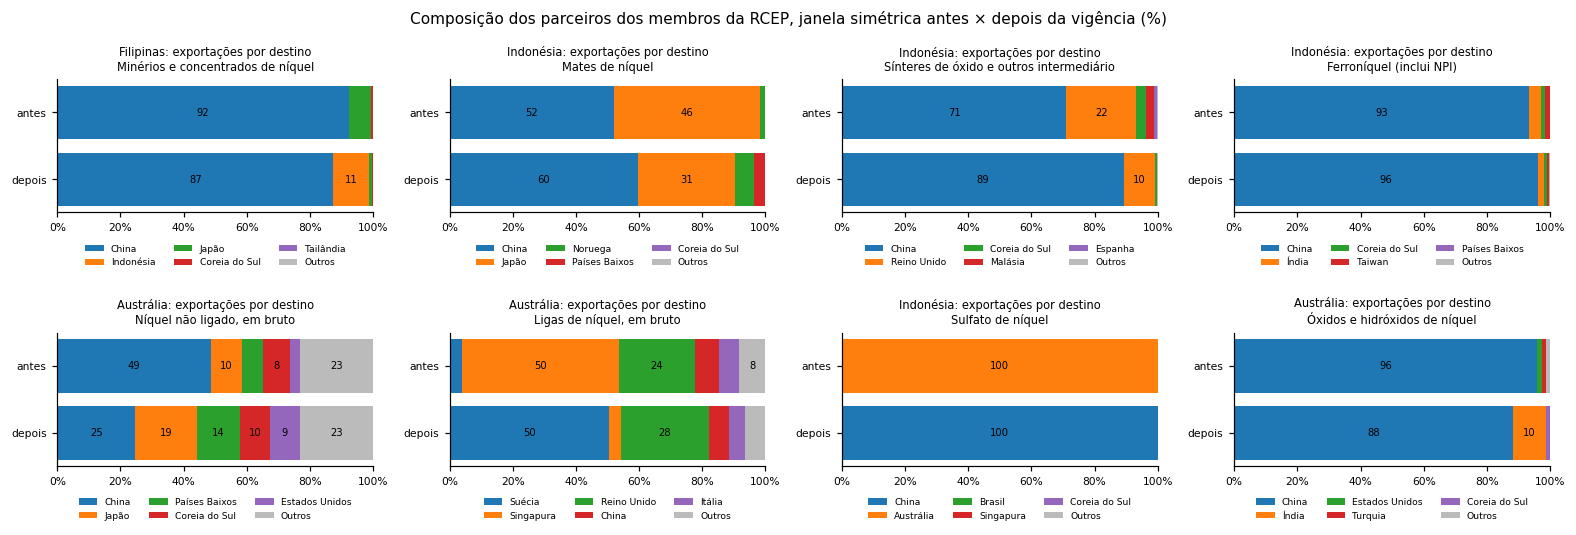

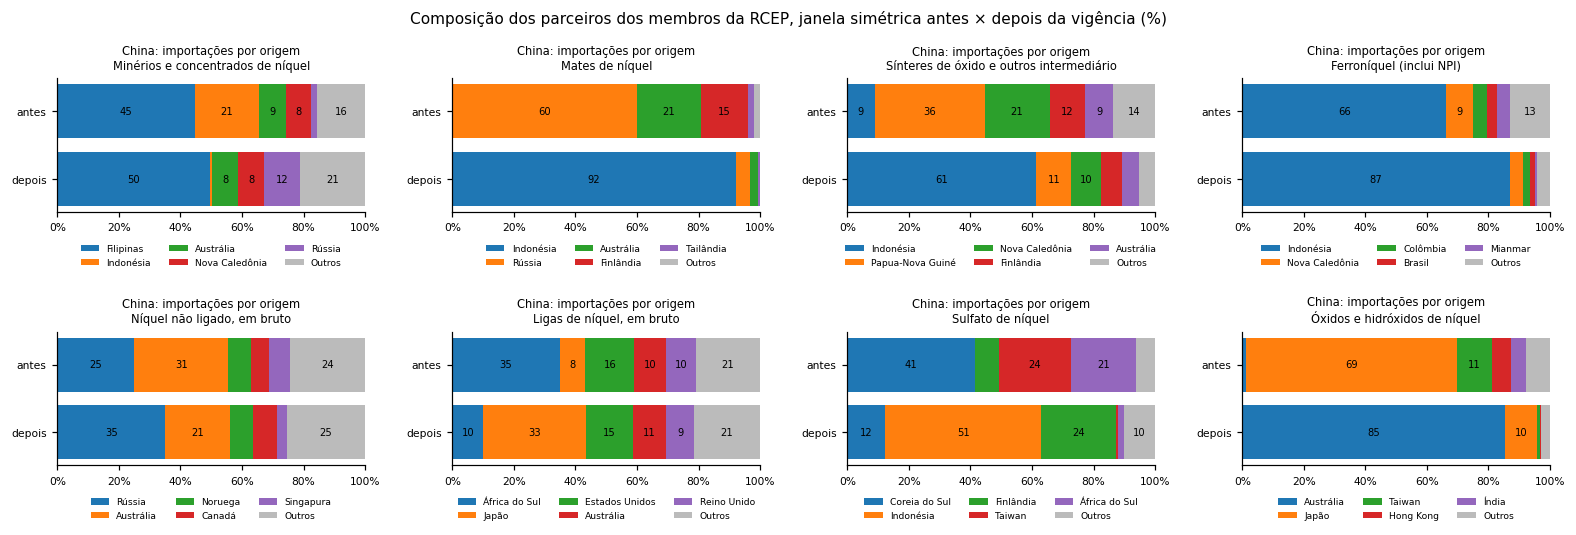

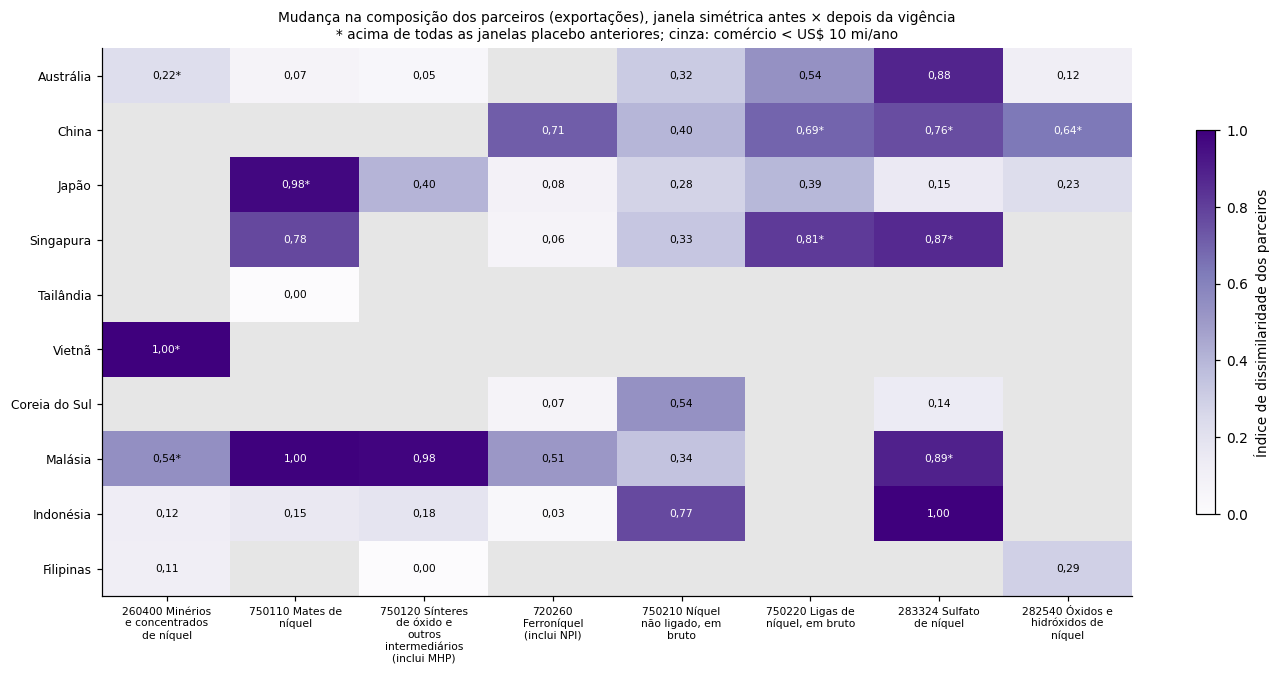

In [28]:
tab_res = pd.concat([r.rename(columns={nivel: "produto_cod"}).assign(nivel_agreg=nivel) for (lado, nivel), r in res_parc.items()], ignore_index=True)
tab_res.insert(1, "membro_nome", tab_res["membro"].map(ind.nome))
for col in ("principal_antes", "principal_depois"):
    tab_res[col + "_nome"] = tab_res[col].map(lambda c: ind.nome(c) if c else "")
salvar_tabela(tab_res, "t09_parceiros_volume_membros")

tab_comp = pd.concat([c.rename(columns={nivel: "produto_cod"}).assign(nivel_agreg=nivel) for (lado, nivel), c in comp_parc.items()], ignore_index=True)
tab_comp["membro_nome"] = tab_comp["membro"].map(ind.nome)
tab_comp["parceiro_nome"] = tab_comp["parceiro"].map(ind.nome)
salvar_tabela(tab_comp[["nivel_agreg", "produto_cod", "lado", "membro", "membro_nome", "parceiro", "parceiro_nome", "grupo_parceiro",
                        "valor_antes", "valor_depois", "share_antes", "share_depois", "var_pp"]], "t10_parceiros_composicao")

for lado, rot in (("exp", "exportações"), ("imp", "importações")):
    for nivel, cods in (("sh6", cfg.SH6_NUCLEO), ("elo", elos_principais)):
        r = res_parc[(lado, nivel)]
        plt.close(gr.heatmap_mudanca(r, nivel, cods, rot, f"fig07_mudanca_parceiros_{lado}_{nivel}"))
        plt.close(gr.heatmap_volume(r, nivel, cods, rot, f"fig08_volume_valor_{lado}_{nivel}", "valor"))
    plt.close(gr.heatmap_volume(res_parc[(lado, "sh6")], "sh6", cfg.SH6_NUCLEO, rot, f"fig09_volume_qtd_{lado}_sh6", "qtd"))

for lado in ("exp", "imp"):
    r = res_parc[(lado, "sh6")].query("relevante and sh6 in @cfg.SH6_NUCLEO")
    pares = [(g.nlargest(1, "valor_medio_depois")["membro"].item(), sh6, lado) for sh6, g in r.groupby("sh6") if len(g)]
    pares = sorted(pares, key=lambda p: cfg.SH6_NUCLEO.index(p[1]))
    gr.barras_composicao(comp_parc[(lado, "sh6")], pares, "sh6", f"fig10_composicao_parceiros_{lado}_sh6_nucleo")
gr.heatmap_mudanca(res_parc[("exp", "sh6")], "sh6", cfg.SH6_NUCLEO, "exportações", "fig07_mudanca_parceiros_exp_sh6");

In [29]:
# Síntese: pares relevantes do núcleo com recomposição acima de todos os placebos
destaque = tab_res.query("relevante and acima_placebos and nivel_agreg == 'sh6' and produto_cod in @cfg.SH6_NUCLEO")
destaque[["membro_nome", "produto_cod", "lado", "valor_medio_antes", "valor_medio_depois", "var_valor_pct",
          "principal_antes_nome", "principal_depois_nome", "indice_mudanca", "placebo_max"]].round(3)

,membro_nome,produto_cod,lado,valor_medio_antes,valor_medio_depois,var_valor_pct,principal_antes_nome,principal_depois_nome,indice_mudanca,placebo_max
0,Austrália,260400,exp,2.414602e+08,3.440754e+08,4.249800e+01,China,China,0.224,0.221
127,China,282540,exp,1.697932e+07,6.317340e+07,2.720610e+02,Suécia,Estados Unidos,0.636,0.589
129,China,283324,exp,5.351711e+06,2.418932e+07,3.519920e+02,Vietnã,Coreia do Sul,0.760,0.516
167,China,750220,exp,2.533656e+07,9.132979e+06,-6.395300e+01,Suécia,Austrália,0.692,0.604
223,Japão,750110,exp,3.940170e+05,2.118523e+07,5.276730e+03,Malásia,Noruega,0.976,0.945
334,Singapura,283324,exp,2.481287e+06,1.709115e+07,5.888020e+02,Malásia,Suécia,0.865,0.192
372,Singapura,750220,exp,1.021818e+07,3.475103e+06,-6.599100e+01,Emirados Árabes,Países Baixos,0.813,0.747
449,Vietnã,260400,exp,1.100000e+01,3.429309e+07,3.117553e+08,Coreia do Sul,China,1.000,0.999
567,Malásia,260400,exp,2.103569e+06,1.201487e+07,4.711660e+02,Alemanha,China,0.544,0.531
570,Malásia,283324,exp,2.446669e+06,1.495193e+07,5.111130e+02,Taiwan,Coreia do Sul,0.891,0.648


## Passo 11. Síntese para o resumo: três figuras

### Tratamento
Recorte na **cadeia mercantil destacada** no artigo, da extração aos insumos para aço inoxidável e
baterias (`config.ELOS_DESTACADOS`: minério, intermediários, níquel refinado e químicos de níquel, nove
SH6). Aço inoxidável e baterias ficam fora da soma, pois o valor deles encobriria o restante da cadeia e
inclui produtos sem relação exclusiva com o níquel. Recortes geográficos: mundo; Ásia (Ásia Oriental,
Sudeste Asiático, Sul da Ásia, Ásia Ocidental e Central); RCEP (15 signatários).

- **R1**: valor anual do comércio mundial por produto (parcela de cada produto no total) e parcela da
  Ásia e da RCEP nas exportações, importações e no comércio interno de cada recorte;
- **R2**: participação dos dez maiores exportadores e importadores no total da cadeia, 2022–2024, com a
  marca de 2019–2021;
- **R3**: participação da Ásia, da RCEP e dos dois maiores países de cada produto em cada produto e no
  total, 2022–2024, com a variação em pontos percentuais desde 2019–2021.

As legendas no padrão ABNT, com a nota que lista os SH6, são gravadas em
`outputs/figuras/legendas_resumo.md`.

In [30]:
cadeia = si.recorte(df)
agregado = si.agregado_anual(cadeia)
part_prod = si.participacao_produtos(cadeia)
part_pais_total = si.participacao_paises_total(cadeia)
part_pais_prod = si.participacao_paises_produto(cadeia)
print("SH6 da cadeia destacada:", si.sh6_destacados())
agregado.assign(valor_mundo_bi=agregado["valor_mundo"] / 1e9)[["ano", "valor_mundo_bi"] + [c for c in agregado if c.startswith("share_")]].round(3)

SH6 da cadeia destacada: ['260400', '750110', '750120', '720260', '750210', '750220', '283324', '282540', '282735']


,ano,valor_mundo_bi,share_exp_asia,share_imp_asia,share_intra_asia,share_exp_rcep,share_imp_rcep,share_intra_rcep
0,2012,32.340,0.235,0.487,0.209,0.334,0.442,0.251
1,2013,32.187,0.250,0.529,0.218,0.360,0.462,0.279
2,2014,36.836,0.271,0.548,0.246,0.362,0.479,0.276
3,2015,32.484,0.313,0.605,0.288,0.367,0.501,0.253
4,2016,23.958,0.239,0.561,0.206,0.287,0.480,0.221
5,2017,25.307,0.264,0.568,0.232,0.321,0.473,0.229
6,2018,28.772,0.265,0.515,0.222,0.341,0.445,0.235
7,2019,31.588,0.289,0.597,0.268,0.351,0.533,0.281
8,2020,32.446,0.329,0.584,0.308,0.377,0.537,0.321
9,2021,45.582,0.349,0.628,0.335,0.417,0.569,0.361


### Validação
1. O total anual da cadeia é igual à soma dos nove SH6 do passo 3.
2. As parcelas dos produtos somam 1 em cada ano; as dos países somam 1 em cada período e sentido.
3. Ásia e RCEP: comércio interno ≤ exportações e ≤ importações do recorte; a parcela da Ásia é igual à
   soma das parcelas dos países asiáticos, e a da RCEP à soma das dos 15 membros.
4. Recálculo manual da participação da Indonésia nas exportações de ferroníquel/NPI em 2022–2024 e da
   China nas importações do total da cadeia em 2019–2021.

In [31]:
soma_sh6 = tot_sh6[tot_sh6["sh6"].isin(si.sh6_destacados())].groupby("ano")["valor"].sum()
assert np.allclose(agregado.set_index("ano")["valor_mundo"], soma_sh6)
ok("total anual da cadeia = soma dos nove SH6 do passo 3")

assert np.allclose(part_prod.groupby("ano")["share"].sum(), 1)
assert np.allclose(part_pais_total.groupby(["lado", "periodo"])["share"].sum(), 1)
ok("parcelas dos produtos (por ano) e dos países (por período e sentido) somam 1")

for bloco in ("asia", "rcep"):
    assert (agregado[f"intra_{bloco}"] <= agregado[[f"exp_{bloco}", f"imp_{bloco}"]].min(axis=1) + 1e-6).all()
paises_asia = paises.loc[paises["macrorregiao"].isin(cfg.ASIA), "iso3"]
for lado in ("exp", "imp"):
    for per in si.PERIODOS:
        p = part_pais_prod.query("lado == @lado and sh6 == 'Total'").set_index("pais")[per]
        assert np.isclose(p.loc["Ásia"], p.reindex(paises_asia).sum())
        assert np.isclose(p.loc["RCEP"], p.reindex(cfg.RCEP).sum())
ok("Ásia e RCEP: comércio interno ≤ exportações e importações; agregados = soma dos países")

x = cadeia[(cadeia["sh6"] == "720260") & cadeia["ano"].isin([2022, 2023, 2024])]
manual = x.loc[x["exp"] == "idn", "valor"].sum() / x["valor"].sum()
funcao = part_pais_prod.query("pais == 'idn' and sh6 == '720260' and lado == 'exp'")["2022–2024"].item()
assert np.isclose(manual, funcao)
x = cadeia[cadeia["ano"].isin([2019, 2020, 2021])]
manual2 = x.loc[x["imp"] == "chn", "valor"].sum() / x["valor"].sum()
funcao2 = part_pais_total.query("pais == 'chn' and lado == 'imp' and periodo == '2019–2021'")["share"].item()
assert np.isclose(manual2, funcao2)
ok(f"Indonésia, 720260, exportações 2022–2024: {manual:.4f}; China, importações da cadeia 2019–2021: {manual2:.4f} (manual = função)")

✔ total anual da cadeia = soma dos nove SH6 do passo 3
✔ parcelas dos produtos (por ano) e dos países (por período e sentido) somam 1
✔ Ásia e RCEP: comércio interno ≤ exportações e importações; agregados = soma dos países
✔ Indonésia, 720260, exportações 2022–2024: 0.7686; China, importações da cadeia 2019–2021: 0.4104 (manual = função)


### Saídas do passo 11

tabela salva: outputs/tabelas/t11_cadeia_agregado_mundo_asia_rcep.csv (13 linhas)
tabela salva: outputs/tabelas/t12_cadeia_participacao_produtos.csv (117 linhas)
tabela salva: outputs/tabelas/t13_cadeia_participacao_paises_total.csv (597 linhas)
tabela salva: outputs/tabelas/t14_cadeia_participacao_paises_por_produto.csv (2225 linhas)


# Legendas das figuras do resumo

## Nota de rodapé (primeira menção à cadeia no texto)
A cadeia considerada reúne nove subposições do Sistema Harmonizado, versão 2012: 260400, minérios de níquel e seus concentrados; 750110, mates de níquel; 750120, sínteres de óxidos de níquel e outros produtos intermediários da metalurgia do níquel; 720260, ferroníquel; 750210, níquel não ligado, em formas brutas; 750220, ligas de níquel, em formas brutas; 283324, sulfatos de níquel; 282540, óxidos e hidróxidos de níquel; 282735, cloreto de níquel. A subposição 720260 inclui o ferro-gusa de níquel (NPI), e a 750120, o precipitado de hidróxido misto (MHP).

## Figura R1 (`figR1_cadeia_mundo_asia_rcep.png`)
**Título:** Comércio mundial da cadeia do níquel, por produto e por origem e destino em relação à RCEP (2012–2024)

Fonte: elaboração própria com dados do BACI-CEPII (HS2012), obtidos no Observatório de Complexidade Econômica.

Nota: subposições do Sistema Harmonizado (versão 2012) consideradas: 260

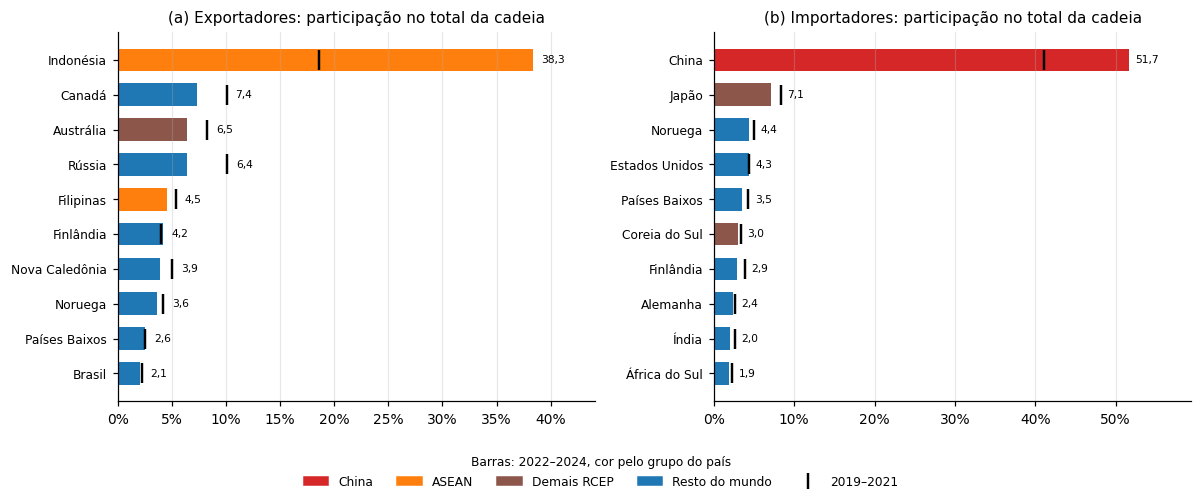

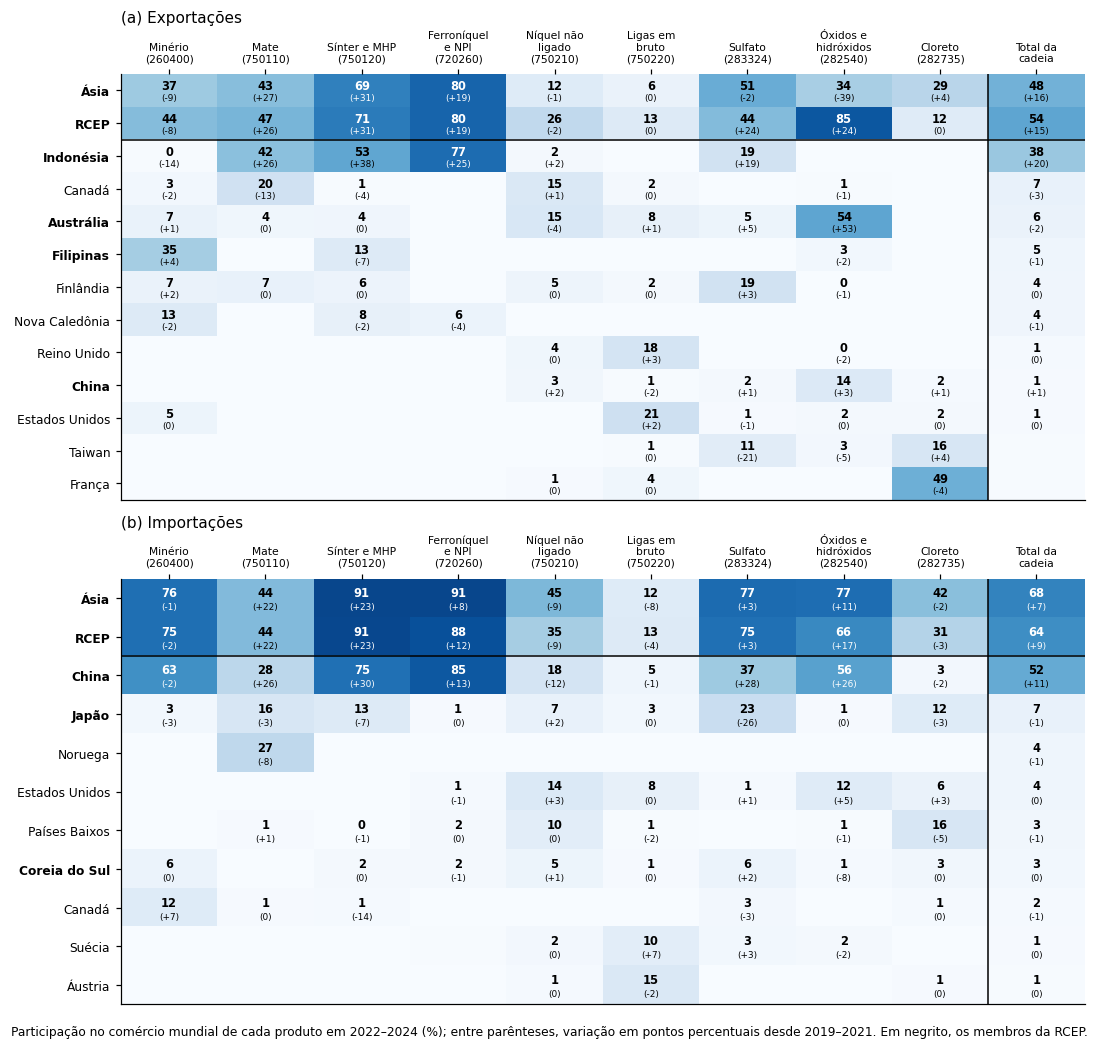

In [32]:
salvar_tabela(agregado, "t11_cadeia_agregado_mundo_asia_rcep")
salvar_tabela(part_prod, "t12_cadeia_participacao_produtos")
salvar_tabela(part_pais_total, "t13_cadeia_participacao_paises_total")
salvar_tabela(part_pais_prod, "t14_cadeia_participacao_paises_por_produto")

# a figura R1 é gerada no passo 11b, que calcula os tipos de fluxo do painel b
si.figura_r2(part_pais_total)
si.figura_r3(part_pais_prod)
(cfg.DIR_FIG / "legendas_resumo.md").write_text(si.legendas(agregado), encoding="utf-8")
print(si.legendas(agregado))

## Passo 11b. Membros da RCEP: posição no agregado e peso do comércio intrabloco

### Tratamento
- **R2 (lollipop)**: participação média anual de cada membro nas exportações e importações mundiais do
  total da cadeia destacada, em 2019–2021 (○) e 2022–2024 (●). **No texto do artigo, 2022 é o marco para
  todos os membros** (`parceiros.entrada(unica=True)`), inclusive Indonésia e Filipinas, que aderiram em 2023;
  os passos 6 a 10 mantêm as datas de cada membro. Substitui no texto a versão em barras do passo 11.
- **Tabela de parceiros do texto** (t19): `parceiros.resumo(..., unica=True)` para os fluxos citados.
- **R4**: peso dos parceiros da RCEP no comércio dos membros, (X_rr + M_rr) / (X_r + M_r), por ano e por
  membro antes e depois da vigência, na cadeia e em **todos os produtos**; e a parcela do comércio
  interno ao bloco no comércio mundial. O comércio de todos os produtos vem de
  `extracao.bilateral_total()`, agregação por ano × exportador × importador de toda a base (cache
  `data/processed/baci_bilateral_total.parquet`).
- **R1, painel b** (regravada aqui): parcela de cada tipo de fluxo no comércio mundial da cadeia, segundo o
  pertencimento do exportador e do importador à RCEP, com ASEAN → China separado (`si.fluxos_por_tipo`).
- **R5**: mapa dos 20 maiores fluxos bilaterais do total da cadeia, 2019–2021 e 2022–2024.

In [33]:
bilateral = ex.bilateral_total()
ad_agregado = si.antes_depois_agregado(cadeia)
intra_anual, intra_membros = si.importancia_intra(cadeia, bilateral)
tipos_fluxo = si.fluxos_por_tipo(cadeia)
res_unica = pd.concat([pa.resumo(df, "sh6", lado, unica=True) for lado in ("exp", "imp")], ignore_index=True)
intra_anual.pivot(index="ano", columns="recorte", values=["parcela_intra_membros", "intra_no_mundo"]).round(3)

parcela_intra_membros        intra_no_mundo       
recorte                cadeia  total         cadeia  total
ano                                                       
2012                    0.648  0.433          0.251  0.118
2013                    0.679  0.425          0.279  0.115
2014                    0.656  0.422          0.276  0.115
2015                    0.583  0.424          0.253  0.118
2016                    0.577  0.424          0.221  0.117
2017                    0.577  0.429          0.229  0.120
2018                    0.598  0.430          0.235  0.122
2019                    0.636  0.433          0.281  0.123
2020                    0.703  0.437          0.321  0.128
2021                    0.733  0.435          0.361  0.127
2022                    0.773  0.429          0.423  0.123
2023                    0.809  0.421          0.480  0.118
2024                    0.835  0.424          0.526  0.123

### Validação
1. A soma anual do bilateral total é igual ao total anual da base (`extracao.totais_anuais`).
2. Na cadeia, a parcela do comércio interno no mundo é igual à do passo 11 (`share_intra_rcep`).
3. As parcelas por membro ficam entre 0 e 1 e, no conjunto dos membros, o comércio com a RCEP não
   excede o comércio total.
4. Recálculo manual: participação da Indonésia nas exportações mundiais da cadeia em 2022–2024 (média
   das parcelas anuais) e parcela da RCEP no comércio da cadeia da China em 2022–2024.
5. Os tipos de fluxo somam o total anual da cadeia, e ASEAN → China mais os demais fluxos entre membros
   igualam o comércio interno à RCEP do passo 11.
6. Marco único: todas as janelas são 2019–2021 e 2022–2024, com cinco placebos; recálculo manual do índice
   dos destinos das exportações indonésias de mates.

In [34]:
tot_base = ex.totais_anuais().set_index("ano")["valor"]
assert np.allclose(bilateral.groupby("ano")["valor"].sum(), tot_base)
ok("bilateral total = total anual da base em todos os anos")

ia = intra_anual.query("recorte == 'cadeia'").set_index("ano")["intra_no_mundo"]
assert np.allclose(ia, agregado.set_index("ano")["share_intra_rcep"])
ok("comércio interno à RCEP na cadeia = passo 11")

for col in ("parcela_antes", "parcela_depois"):
    assert intra_membros[col].dropna().between(0, 1).all()
assert (intra_anual["parcela_intra_membros"].between(0, 1)).all()
ok("parcelas dos membros entre 0 e 1")

anos = [2022, 2023, 2024]
x = cadeia[cadeia["ano"].isin(anos)]
manual = np.mean([x.loc[(x["ano"] == a) & (x["exp"] == "idn"), "valor"].sum() / x.loc[x["ano"] == a, "valor"].sum() for a in anos])
funcao = ad_agregado.query("pais == 'idn' and lado == 'exp'")["share_depois"].item()
assert np.isclose(manual, funcao)
x = cadeia[cadeia["ano"].isin([2022, 2023, 2024])]
chn = x[(x["exp"] == "chn") | (x["imp"] == "chn")]
manual2 = chn.loc[chn["exp"].isin(cfg.RCEP) & chn["imp"].isin(cfg.RCEP), "valor"].sum() / chn["valor"].sum()
funcao2 = intra_membros.query("pais == 'chn' and recorte == 'cadeia'")["parcela_depois"].item()
assert np.isclose(manual2, funcao2)
ok(f"recálculo manual: Indonésia {manual:.1%} das exportações (2022–2024); RCEP {manual2:.1%} do comércio da cadeia da China (2022–2024)")

assert np.allclose(tipos_fluxo.sum(axis=1), agregado.set_index("ano")["valor_mundo"])
intra_tipos = tipos_fluxo[["ASEAN → China", "outros fluxos entre membros da RCEP"]].sum(axis=1)
assert np.allclose(intra_tipos, agregado.set_index("ano")["intra_rcep"])
ok("tipos de fluxo somam o total da cadeia; ASEAN → China + outros intra-RCEP = comércio interno do passo 11")

assert (ad_agregado["anos_antes"] == "2019–2021").all() and (ad_agregado["anos_depois"] == "2022–2024").all()
assert (res_unica["anos_antes"] == "2019–2021").all() and (res_unica["anos_depois"] == "2022–2024").all()
assert res_unica["placebo_n"].max() == 5
f = df[(df["sh6"] == "750110") & (df["exp"] == "idn")]
sa = f[f["ano"].isin([2019, 2020, 2021])].groupby("imp")["valor"].sum(); sa = sa / sa.sum()
sb = f[f["ano"].isin([2022, 2023, 2024])].groupby("imp")["valor"].sum(); sb = sb / sb.sum()
D = 0.5 * sa.sub(sb, fill_value=0).abs().sum()
assert np.isclose(D, res_unica.query("membro == 'idn' and sh6 == '750110' and lado == 'exp'")["indice_mudanca"].item())
ok(f"marco único 2022: janelas 2019–2021 × 2022–2024 em todos os membros; D manual dos mates indonésios = {D:.3f}")

✔ bilateral total = total anual da base em todos os anos
✔ comércio interno à RCEP na cadeia = passo 11
✔ parcelas dos membros entre 0 e 1
✔ recálculo manual: Indonésia 38.8% das exportações (2022–2024); RCEP 77.2% do comércio da cadeia da China (2022–2024)
✔ tipos de fluxo somam o total da cadeia; ASEAN → China + outros intra-RCEP = comércio interno do passo 11
✔ marco único 2022: janelas 2019–2021 × 2022–2024 em todos os membros; D manual dos mates indonésios = 0.688


### Saídas do passo 11b

tabela salva: outputs/tabelas/t15_membros_antes_depois_agregado.csv (28 linhas)
tabela salva: outputs/tabelas/t16_intra_rcep_anual_cadeia_e_total.csv (26 linhas)
tabela salva: outputs/tabelas/t17_intra_rcep_membros_cadeia_e_total.csv (28 linhas)


tabela salva: outputs/tabelas/t18_cadeia_valor_por_tipo_de_fluxo.csv (13 linhas)
tabela salva: outputs/tabelas/t19_parceiros_marco_2022.csv (1559 linhas)


,Membro e fluxo,Produto,Valor antes,Valor depois,"Principal parceiro, antes e depois",Índice,Placebo máx.
0,"China, importações",Mates,"0,13","2,55",Rússia (60%); Indonésia (92%),"0,92*","0,81"
1,"China, importações",Sínteres e MHP,"1,50","4,67",Papua-Nova Guiné (36%); Indonésia (61%),"0,53*","0,41"
2,"China, importações",Sulfato,"0,07","0,53",Coreia do Sul (41%); Indonésia (51%),"0,77*","0,57"
3,"China, importações",Ferroníquel e NPI,"6,69","15,29",Indonésia (66%); Indonésia (87%),"0,21","0,49"
4,"China, importações",Minério,"2,73","3,16",Filipinas (45%); Filipinas (50%),"0,25","0,56"
5,"Indonésia, exportações",Ferroníquel e NPI,"4,86","13,89",China (91%); China (96%),"0,05","0,84"
6,"Indonésia, exportações",Sínteres e MHP,"0,50","3,30",Reino Unido (64%); China (87%),"0,61","0,68"
7,"Indonésia, exportações",Mates,"0,83","3,83",Japão (100%); China (61%),"0,69*","0,09"
8,"Filipinas, exportações",Minério,"1,30","1,77",China (94%); China (89%),"0,09*","0,08"


4721

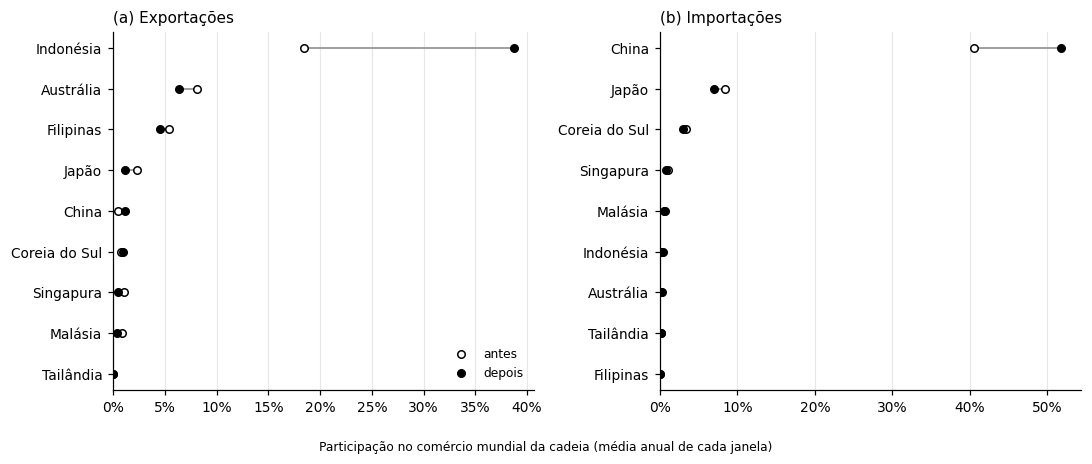

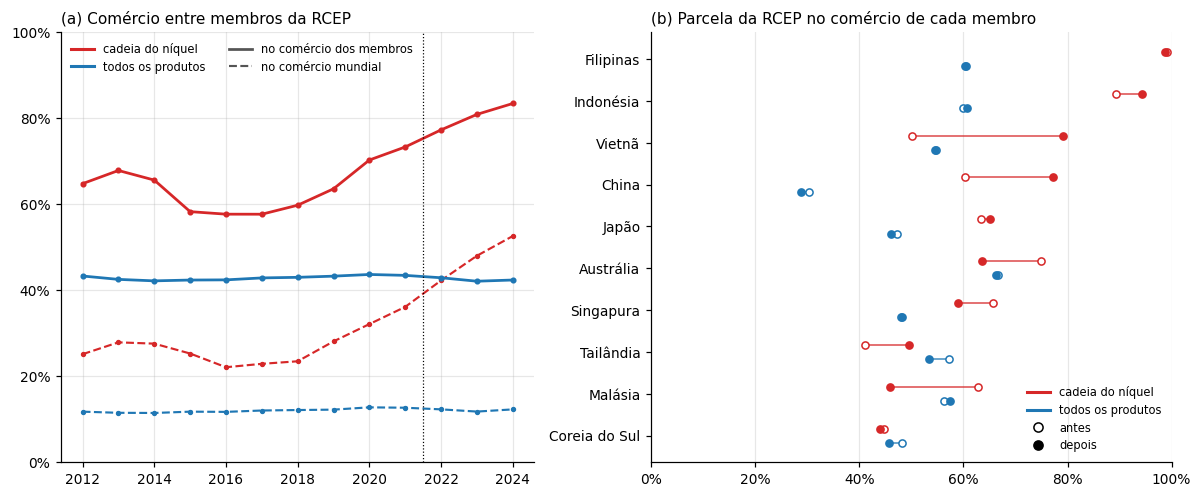

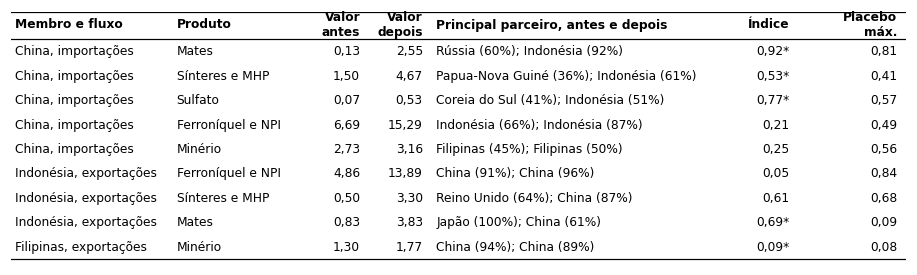

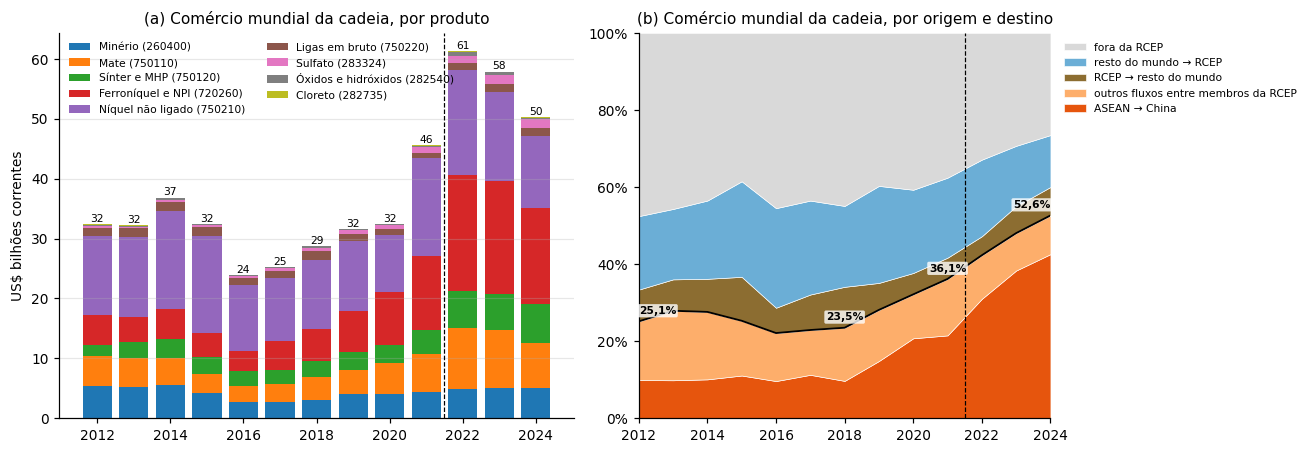

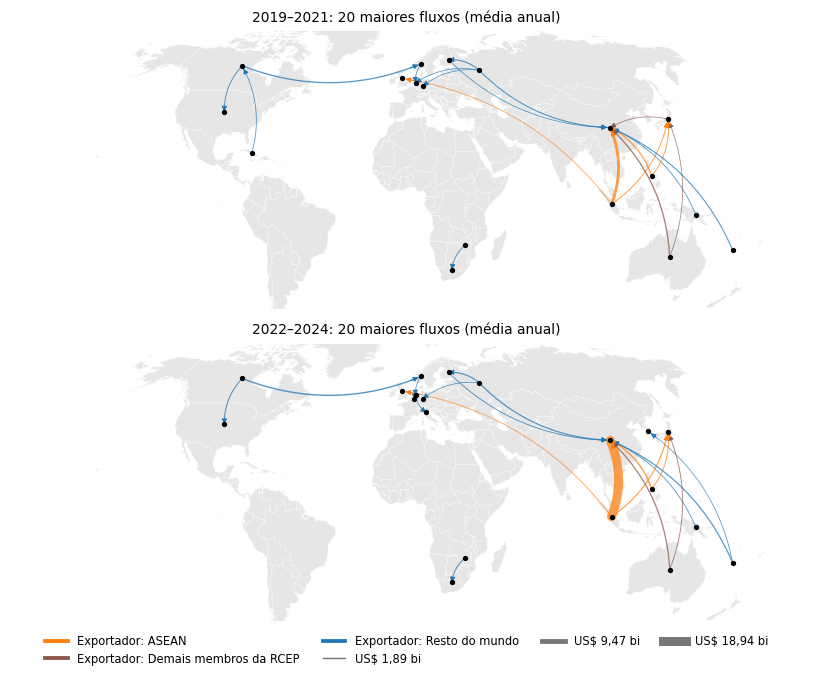

In [35]:
salvar_tabela(ad_agregado, "t15_membros_antes_depois_agregado")
salvar_tabela(intra_anual, "t16_intra_rcep_anual_cadeia_e_total")
salvar_tabela(intra_membros, "t17_intra_rcep_membros_cadeia_e_total")
si.figura_r2_lollipop(ad_agregado)
si.figura_r4(intra_anual, intra_membros)
salvar_tabela(tipos_fluxo.reset_index(), "t18_cadeia_valor_por_tipo_de_fluxo")
salvar_tabela(res_unica, "t19_parceiros_marco_2022")
tab_parceiros = si.tabela_parceiros(res_unica)  # Tabela 1 do capítulo, gravada como imagem
assert len(tab_parceiros) == len(si.LINHAS_TABELA_PARCEIROS)
si.figura_tabela_parceiros(tab_parceiros)
display(tab_parceiros)
si.figura_r1(part_prod, tipos_fluxo)
si.figura_r5_mapa(cadeia, base_mapa)
(cfg.DIR_FIG / "legendas_resumo.md").write_text(si.legendas(agregado), encoding="utf-8")

## Passo 12a. Planilha para compartilhar

`outputs/planilha_artigo_niquel_rcep.xlsx`, gerada por `planilha.gravar`: aba **Leia-me** (fonte, unidades,
convenções e SH6), aba **Dados brutos** (fluxos bilaterais dos nove SH6 da cadeia destacada) e aba
**Métricas** (tabelas de cada figura, da tabela e das séries citadas no capítulo, na ordem do texto).

### Validação
Os dados brutos somam o total anual da cadeia do passo 11, e a última linha do bloco de tipos de fluxo
reproduz o comércio interno à RCEP de 2024.

In [36]:
from niquel import planilha as pl

brutos, blocos_planilha = pl.gravar(df, bilateral)
assert np.allclose(brutos.groupby("Ano")["Valor (US$ correntes)"].sum(), agregado.set_index("ano")["valor_mundo"])
tipos_pl = dict((t, x) for t, _, x in blocos_planilha)[
    "4. Comércio mundial da cadeia por origem e destino em relação à RCEP (% do valor mundial)"]
assert np.isclose(tipos_pl.iloc[-1, -1], agregado.set_index("ano").loc[2024, "share_intra_rcep"] * 100)
ok(f"planilha gravada: {len(brutos):,} fluxos brutos e {len(blocos_planilha)} blocos de métricas")

✔ planilha gravada: 57,059 fluxos brutos e 15 blocos de métricas


## Passo 12. Inventário das saídas

In [37]:
with pd.ExcelWriter(cfg.DIR_TAB / "tabelas_artigo.xlsx") as xls:
    for nome, t in TABELAS.items():
        t.to_excel(xls, sheet_name=nome[:31], index=False)
print("planilha consolidada: outputs/tabelas/tabelas_artigo.xlsx")

figs = sorted(p.name for p in cfg.DIR_FIG.glob("*.png"))
print(f"\n{len(figs)} figuras em outputs/figuras/:")
print("\n".join("  " + f for f in figs))

planilha consolidada: outputs/tabelas/tabelas_artigo.xlsx

78 figuras em outputs/figuras/:
  fig01_valor_anual_por_elo.png
  fig02_rcep_antes_depois_exp_sh6_nucleo.png
  fig02_rcep_antes_depois_imp_sh6_nucleo.png
  fig03_rcep_antes_depois_exp_elos.png
  fig03_rcep_antes_depois_imp_elos.png
  fig04_intra_rcep_elos.png
  fig05_intra_rcep_sh6_nucleo.png
  fig06_matriz_grupos_sh6_nucleo.png
  fig07_mudanca_parceiros_exp_elo.png
  fig07_mudanca_parceiros_exp_sh6.png
  fig07_mudanca_parceiros_imp_elo.png
  fig07_mudanca_parceiros_imp_sh6.png
  fig08_volume_valor_exp_elo.png
  fig08_volume_valor_exp_sh6.png
  fig08_volume_valor_imp_elo.png
  fig08_volume_valor_imp_sh6.png
  fig09_volume_qtd_exp_sh6.png
  fig09_volume_qtd_imp_sh6.png
  fig10_composicao_parceiros_exp_sh6_nucleo.png
  fig10_composicao_parceiros_imp_sh6_nucleo.png
  figR1_cadeia_mundo_asia_rcep.png
  figR2_membros_antes_depois.png
  figR2_paises_total_cadeia.png
  figR3_paises_por_produto.png
  figR4_importancia_intra_rcep.png
  

## Notas

- **Dicionário das tabelas.** `share` é fração (0–1) do comércio mundial do produto no ano; `var_pp` é a
  diferença em pontos percentuais; `valor` em US$ correntes; `qtd` em toneladas; `valor_unit` em US$/t;
  `nivel_agreg` indica se `produto_cod` é um SH6 ou um elo.
- **Elo aproximado.** "9. Cátodos (aproximado)" (SH 284190) contém outros sais além dos materiais de
  cátodo e não entra nas sínteses (figuras 2 a 5); aparece apenas no seu painel próprio.
- **Interpretação das comparações antes/depois.** Elas descrevem mudanças de participação em torno da
  data de vigência e não isolam o efeito do acordo, que coincide com a alta de preços de 2022, a
  expansão do refino indonésio e a proibição de exportação de minério adotada pela Indonésia em 2020 (conferir a norma antes de citá-la no texto).
- **Reprodução.** Para mudar códigos, datas ou regiões, editar `src/niquel/config.py`, rodar o passo 1
  com `forcar=True` (e `ex.tabela_paises(forcar=True)` se mudar `NOMES_PT` ou `MACRORREGIAO`) e
  reexecutar o notebook inteiro.